# EXP-RESNET50-TRANSFER-5SEEDS-008: frozen-backbone transfer ablation

**NOT_EXECUTED.** This is a lower-capacity ResNet50 ImageNet transfer run on
the same frozen V08 dataset. Both stages train only the classification head;
Stage 2 is a short, lower-learning-rate refinement. No backbone weights or
BatchNorm statistics are updated. The 006 and 007 experiments are preserved.

This tests whether ResNet50 fine-tuning caused the Train/Validation gap seen
in the partial 006 logs. High accuracy at the end of epoch 1 can still be
normal: it follows about 300 gradient steps on pretrained ImageNet features.
The pre-fit, first-batch, balanced Train probe, Validation and real holdout
diagnostics help distinguish learning speed from overfitting.

Five seeds, Validation-only selection, Final Test and the historical real
holdout remain enabled. Test and holdout run only after the selection lock.
Both result ZIPs include this exact 008 notebook. No 008 result is claimed.


In [1]:
import sys
print("Python:", sys.executable)

!nvidia-smi

Python: /usr/bin/python3
Mon Oct 19 17:06:29 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA RTX PRO 6000 Blac...    Off |   00000000:05:00.0 Off |                    0 |
| N/A   34C    P0             49W /  600W |       0MiB /  97887MiB |      0%      Default |
|                                         |                        |             Disabled |
+----------------------

In [2]:

# ============================================================
# 01. IMPORT LIBRARIES
# ============================================================

import os
import sys
import io
import gc
import json
import time
import random
import shutil
import platform
import zipfile
import hashlib
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    ConfusionMatrixDisplay,
)

from IPython.display import display
import ipywidgets as widgets

MATRIX_CMAP = LinearSegmentedColormap.from_list(
    "readable_blues", ["#ffffff", "#dbeafe", "#93c5fd"]
)

plt.rcParams.update({
    "text.color": "black", "axes.labelcolor": "black",
    "axes.titlecolor": "black", "xtick.color": "black", "ytick.color": "black",
})

print("Imports completed.")


Imports completed.


In [3]:

# ============================================================
# 02. ENVIRONMENT INFORMATION
# ============================================================

print(f"Date              : {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Python            : {sys.version.split()[0]}")
print(f"TensorFlow        : {tf.__version__}")
print(f"Keras             : {keras.__version__ if hasattr(keras, '__version__') else 'tf.keras'}")
RUNTIME = ("Windows" if os.name == "nt" else "Kaggle" if Path("/kaggle/working").is_dir() else "Colab" if Path("/content").is_dir() else platform.system())
print(f"Runtime           : {RUNTIME}")
print(f"OS                : {platform.platform()}")

gpus = tf.config.list_physical_devices("GPU")
print(f"GPU Count         : {len(gpus)}")
if RUNTIME == "Colab" and not gpus:
    raise RuntimeError("Colab has no GPU. Select a GPU runtime and rerun from the first cell.")

for i, gpu in enumerate(gpus):
    print(f"GPU {i}             : {gpu}")

if gpus:
    strategy = tf.distribute.OneDeviceStrategy(device="/GPU:0")
else:
    strategy = tf.distribute.OneDeviceStrategy(device="/CPU:0")

print(f"Strategy          : {strategy.__class__.__name__}")
print(f"Replicas          : {strategy.num_replicas_in_sync}")


Date              : 2026-10-19 17:06:31
Python            : 3.13.15
TensorFlow        : 2.21.0
Keras             : 3.13.2
Runtime           : Colab
OS                : Linux-6.6.122+-x86_64-with-glibc2.39
GPU Count         : 1
GPU 0             : PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')
Strategy          : OneDeviceStrategy
Replicas          : 1


In [4]:

# ============================================================
# 03. CONFIGURATION — EXP-008
# ============================================================

NOTEBOOK_VERSION = "008"
NOTEBOOK_SOURCE_PATH = None  # Optional path to this exact 007 .ipynb on Drive.
EXPERIMENT_ID = "EXP-RESNET50-TRANSFER-5SEEDS-008"
DATASET_VERSION = "Cashew_dataV08_real_val"
DATASET_ARCHIVE_NAME = "CashewData_Split (8).zip"
DATASET_ARCHIVE_FILE_ID = None  # Mounted Drive path is authoritative on Colab.
DATASET_ARCHIVE_OVERRIDE = None  # Optional exact ZIP path, useful on Kaggle.



EXPECTED_CLASSES = [
    "anthracnose",
    "healthy",
    "leaf_miner",
    "red_rust",
    "not_cashew_leaf",
]

EXPECTED_COUNTS = {
    "anthracnose": {
        "train": 939,
        "val": 308,
        "test": 122,
        "total": 1369,
    },

    "healthy": {
        "train": 803,
        "val": 216,
        "test": 118,
        "total": 1137,
    },

    "leaf_miner": {
        "train": 875,
        "val": 264,
        "test": 132,
        "total": 1271,
    },

    "not_cashew_leaf": {
        "train": 1101,
        "val": 314,
        "test": 156,
        "total": 1571,
    },

    "red_rust": {
        "train": 1072,
        "val": 328,
        "test": 158,
        "total": 1558,
    },
}

EXPECTED_TOTALS = {
    "train": 4790,
    "val": 1430,
    "test": 686,
    "total": 6906,
}

STRICT_DATASET_CHECK = True
EXPECTED_REAL_FILENAME_COUNTS = {"train": 135, "val": 35, "test": 28}


# Removed files that must not appear in Split (8).
REQUIRED_ABSENT_IMAGES = [
    "val/leaf_miner/leaf_miner_1056.jpg",
    "val/leaf_miner/leaf_miner_1091.jpg",
    "test/not_cashew_leaf/not_cashew_leaf_1514.JPG",
]

# ------------------------------------------------------------
# Fixed five-seed, two-stage transfer protocol
# ------------------------------------------------------------
SEEDS = [42, 123, 2026, 3407, 7777]
IMG_SIZE = 224
BATCH_SIZE = 16
MODEL_NAME = "ResNet50"
TRAINING_MODE = "ImageNet Transfer, two-stage"
PRETRAINED_WEIGHTS = "imagenet"
HEAD_DROPOUT = 0.40
WEIGHT_DECAY = 1e-4
STAGE1_LR, STAGE1_EPOCHS = 3e-4, 12
STAGE1_EARLY_PATIENCE, STAGE1_REDUCE_PATIENCE, STAGE1_MIN_LR = 4, 2, 1e-6
STAGE2_LR, STAGE2_EPOCHS = 3e-5, 6
STAGE2_EARLY_PATIENCE, STAGE2_REDUCE_PATIENCE, STAGE2_MIN_LR = 2, 1, 1e-7
LR_REDUCTION_FACTOR = 0.5
EXPECTED_MANIFEST_SHA256 = "1810d7e654fede9c8f6a9d08a4078be7882492db2d2d842a19b5320b9aae356b"

RUN_PIPELINE_SMOKE = True
RUN_FULL_TRAINING = True
RUN_FINAL_TEST = True
RUN_REAL_HOLDOUT = True  # Historical, already inspected 48-image set.
REAL_HOLDOUT_ARCHIVE_NAME = "RL_Cashew_holdout.zip"
REAL_HOLDOUT_ARCHIVE_SHA256 = "BDDCB61CA9AF6111E0B26DB7876D0A3309C587AEAFFAEF49B7A9D2D162309165"
REAL_HOLDOUT_EXPECTED_COUNTS = {"anthracnose": 13, "healthy": 5, "leaf_miner": 24, "red_rust": 7}  # 49 source; one Test duplicate excluded
REAL_HOLDOUT_ARCHIVE_OVERRIDE = None

# The evaluation cells assert the immutable Validation lock after all five seeds.

# Separate result namespace; earlier experiments are never modified.
if RUNTIME == "Windows":
    PROJECT_ROOT = Path(r"D:\Study\KhoaLuanTotNghiep\Resource")
    RESULTS_ROOT = PROJECT_ROOT / "training_results" / "current_dataset"
elif RUNTIME == "Kaggle":
    PROJECT_ROOT = Path("/kaggle/working")
    RESULTS_ROOT = PROJECT_ROOT / "training_results" / "current_dataset"
elif RUNTIME == "Colab":
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_ROOT = Path("/content")
    DRIVE_PROJECT_DIR = Path("/content/drive/MyDrive/Cashew_Leaf_model_result")
    DRIVE_DATASET_ARCHIVE = DRIVE_PROJECT_DIR / "Dataset" / DATASET_ARCHIVE_NAME
    if not DRIVE_PROJECT_DIR.is_dir():
        raise FileNotFoundError(DRIVE_PROJECT_DIR)
    RESULTS_ROOT = DRIVE_PROJECT_DIR / "training_results" / "current_dataset"
else:
    raise RuntimeError(f"Unsupported runtime: {RUNTIME}")

OUT_DIR = RESULTS_ROOT / EXPERIMENT_ID
AGGREGATE_DIR = OUT_DIR / "aggregate"
PANEL_DIR = OUT_DIR / "figures" / "panels"
MODEL_PACKAGE_DIR = OUT_DIR / "model_package"
CODE_PACKAGE_DIR = OUT_DIR / "code"
ENV_DIR = OUT_DIR / "environment"
for directory in (OUT_DIR, AGGREGATE_DIR, PANEL_DIR, MODEL_PACKAGE_DIR, CODE_PACKAGE_DIR, ENV_DIR):
    directory.mkdir(parents=True, exist_ok=True)
if not RUN_FULL_TRAINING and not (OUT_DIR / "validation_selection_lock.json").is_file():
    raise FileNotFoundError("Evaluation-only mode requires a completed EXP-008 Validation lock.")
print("Experiment:", EXPERIMENT_ID)
print("Dataset:", DATASET_ARCHIVE_NAME, "| seeds:", SEEDS)
print("Flags:", RUN_FULL_TRAINING, RUN_FINAL_TEST, RUN_REAL_HOLDOUT)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Experiment: EXP-RESNET50-TRANSFER-5SEEDS-008
Dataset: CashewData_Split (8).zip | seeds: [42, 123, 2026, 3407, 7777]
Flags: True True True


In [5]:

# ============================================================
# 04. REPRODUCIBILITY
# ============================================================

def set_global_seed(seed: int):
    os.environ["PYTHONHASHSEED"] = str(seed)

    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

    # Đồng bộ Python / NumPy / TensorFlow theo Keras.
    try:
        keras.utils.set_random_seed(seed)
    except Exception:
        pass

    print(f"Global seed set to: {seed}")


try:
    tf.config.experimental.enable_op_determinism()
    print("Deterministic operations: ENABLED")
except Exception as e:
    print("Deterministic operations: unavailable")
    print("Reason:", e)


Deterministic operations: ENABLED


In [6]:
# ============================================================
# 05. LOAD FROZEN SPLIT (8) FROM THE EXACT ZIP
# ============================================================

EXPECTED_ZIP_SHA256 = "75c5928b2f6432aca901bc16831e91f9aa4bdacc1e2ff536753d71da60c147e7"

if DATASET_ARCHIVE_OVERRIDE is not None:
    archive_for_hash = Path(DATASET_ARCHIVE_OVERRIDE)
elif RUNTIME == "Windows":
    archive_for_hash = PROJECT_ROOT.parent / "Dataset" / DATASET_ARCHIVE_NAME
elif RUNTIME == "Colab":
    archive_for_hash = DRIVE_DATASET_ARCHIVE
else:  # Kaggle input dataset should contain the original Split (8) ZIP.
    archive_candidates = sorted(Path("/kaggle/input").rglob(DATASET_ARCHIVE_NAME))
    if len(archive_candidates) != 1:
        raise RuntimeError(
            f"Expected one {DATASET_ARCHIVE_NAME} under /kaggle/input; "
            f"found: {archive_candidates}. Set DATASET_ARCHIVE_OVERRIDE if needed."
        )
    archive_for_hash = archive_candidates[0]

if not archive_for_hash.is_file():
    raise FileNotFoundError(
        f"Split (8) ZIP missing: {archive_for_hash}. "
        "Upload/mount the exact archive or set DATASET_ARCHIVE_OVERRIDE."
    )

digest = hashlib.sha256()
with archive_for_hash.open("rb") as stream:
    for block in iter(lambda: stream.read(8 << 20), b""):
        digest.update(block)
DATASET_ZIP_SHA256 = digest.hexdigest()
if DATASET_ZIP_SHA256 != EXPECTED_ZIP_SHA256:
    raise ValueError(
        f"Split (8) ZIP SHA256 mismatch: {DATASET_ZIP_SHA256}; "
        f"expected {EXPECTED_ZIP_SHA256}"
    )
print("Verified Split (8) ZIP:", archive_for_hash)
print("Dataset ZIP SHA256:", DATASET_ZIP_SHA256)

# Keep this cache separate from the Split (7) dataset used by version 011.
cache_parent = PROJECT_ROOT / "dataset_cache"
extraction_root = cache_parent / "split_08"
staging_root = cache_parent / "split_08_staging"
DATASET_PATH = extraction_root / "CashewData_Split"
marker = extraction_root / ".archive_sha256"

if extraction_root.exists():
    if not marker.is_file() or marker.read_text(encoding="utf-8").strip() != EXPECTED_ZIP_SHA256:
        raise RuntimeError(
            f"Split (8) cache has no matching completion marker: {extraction_root}. "
            "Inspect it and remove or rename it before retrying."
        )
else:
    if staging_root.exists():
        raise RuntimeError(
            f"Previous Split (8) extraction is incomplete: {staging_root}. "
            "Inspect it and remove or rename it before retrying."
        )
    cache_parent.mkdir(parents=True, exist_ok=True)
    staging_root.mkdir()
    with zipfile.ZipFile(archive_for_hash) as dataset_archive:
        for member in dataset_archive.infolist():
            target = (staging_root / member.filename).resolve()
            if target != staging_root.resolve() and staging_root.resolve() not in target.parents:
                raise ValueError(f"Unsafe path in dataset archive: {member.filename}")
            if not member.filename.startswith("CashewData_Split/"):
                raise ValueError(f"Unexpected Split (8) ZIP root: {member.filename}")
        corrupt_member = dataset_archive.testzip()
        if corrupt_member is not None:
            raise ValueError(f"Dataset ZIP CRC failed: {corrupt_member}")
        print("Extracting Split (8) into:", staging_root)
        dataset_archive.extractall(staging_root)
    if not all((staging_root / "CashewData_Split" / name).is_dir()
               for name in ("train", "val", "test")):
        raise RuntimeError("Split (8) ZIP has no complete train/val/test directory tree.")
    (staging_root / ".archive_sha256").write_text(EXPECTED_ZIP_SHA256 + "\n", encoding="utf-8")
    staging_root.rename(extraction_root)

required_splits = [DATASET_PATH / name for name in ("train", "val", "test")]
missing_splits = [str(path) for path in required_splits if not path.is_dir()]
if missing_splits:
    raise FileNotFoundError(f"Split (8) cache is incomplete: {missing_splits}")

TRAIN_DIR = DATASET_PATH / "train"
VAL_DIR = DATASET_PATH / "val"
TEST_DIR = DATASET_PATH / "test"

unexpected_removed_files = [
    DATASET_PATH / Path(relative_path)
    for relative_path in REQUIRED_ABSENT_IMAGES
    if (DATASET_PATH / Path(relative_path)).is_file()
]
if unexpected_removed_files:
    raise ValueError(
        "Split (8) contains files that should be absent:\n" +
        "\n".join(str(path) for path in unexpected_removed_files)
    )

print("\nSelected dataset:", DATASET_PATH)
print("TRAIN_DIR:", TRAIN_DIR)
print("VAL_DIR  :", VAL_DIR)
print("TEST_DIR :", TEST_DIR)


Verified Split (8) ZIP: /content/drive/MyDrive/Cashew_Leaf_model_result/Dataset/CashewData_Split (8).zip
Dataset ZIP SHA256: 75c5928b2f6432aca901bc16831e91f9aa4bdacc1e2ff536753d71da60c147e7

Selected dataset: /content/dataset_cache/split_08/CashewData_Split
TRAIN_DIR: /content/dataset_cache/split_08/CashewData_Split/train
VAL_DIR  : /content/dataset_cache/split_08/CashewData_Split/val
TEST_DIR : /content/dataset_cache/split_08/CashewData_Split/test



# Dataset Audit

Notebook kiểm tra lại toàn bộ ảnh trước khi train.

Nếu:
- có ảnh decode lỗi;
- có file extension lạ;
- class folder sai;
- số lượng khác revision sạch trong `CashewData_Split (8).zip`;

thì notebook sẽ **dừng** khi `STRICT_DATASET_CHECK=True`.


In [7]:

# ============================================================
# 06. DATASET AUDIT + EXACT COUNTS
# ============================================================

VALID_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".gif", ".webp"
}


def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as stream:
        for block in iter(lambda: stream.read(1 << 20), b""):
            digest.update(block)
    return digest.hexdigest()


from PIL import ImageOps
from scipy.fftpack import dct


def phash64(image):
    gray = np.asarray(image.convert("L").resize((32, 32), Image.Resampling.LANCZOS), dtype=np.float32)
    frequencies = dct(dct(gray, axis=0, norm="ortho"), axis=1, norm="ortho")[:8, :8]
    bits = frequencies > np.median(frequencies)
    return int("".join("1" if bit else "0" for bit in bits.flat), 2)


def pixel_hash(image):
    rgb = image.convert("RGB")
    digest = hashlib.sha256()
    digest.update(f"{rgb.width}x{rgb.height}:".encode())
    digest.update(rgb.tobytes())
    return digest.hexdigest()


def audit_split(split_name, split_dir):
    valid_rows = []
    bad_rows = []
    unknown_rows = []

    found_classes = sorted([
        p.name for p in split_dir.iterdir()
        if p.is_dir()
    ])

    if found_classes != sorted(EXPECTED_CLASSES):
        raise ValueError(
            f"Class folders của {split_name} không đúng.\n"
            f"Expected: {sorted(EXPECTED_CLASSES)}\n"
            f"Found   : {found_classes}"
        )

    for label, class_name in enumerate(EXPECTED_CLASSES):
        class_dir = split_dir / class_name

        for path in sorted(class_dir.rglob("*")):
            if not path.is_file():
                continue

            ext = path.suffix.lower()

            if ext not in VALID_EXTENSIONS:
                unknown_rows.append({
                    "split": split_name,
                    "class": class_name,
                    "path": str(path),
                    "extension": ext,
                })
                continue

            try:
                with Image.open(path) as img:
                    img.verify()

                with Image.open(path) as img:
                    image = ImageOps.exif_transpose(img)
                    image.load()
                    pixels_sha = pixel_hash(image)
                    perceptual_hash = phash64(image)

                valid_rows.append({
                    "split": split_name,
                    "class": class_name,
                    "label": label,
                    "path": str(path),
                    "relative_path": path.relative_to(DATASET_PATH).as_posix(),
                    "sha256": sha256_file(path),
                    "pixel_sha256": pixels_sha,
                    "phash64": perceptual_hash,
                    "is_real_filename": path.name.casefold().startswith("real_"),
                })

            except Exception as e:
                bad_rows.append({
                    "split": split_name,
                    "class": class_name,
                    "path": str(path),
                    "error": str(e),
                })

    return valid_rows, bad_rows, unknown_rows


all_valid = []
all_bad = []
all_unknown = []

for split_name, split_dir in {
    "train": TRAIN_DIR,
    "val": VAL_DIR,
    "test": TEST_DIR,
}.items():

    print(f"Checking {split_name}...")

    valid_rows, bad_rows, unknown_rows = audit_split(
        split_name,
        split_dir
    )

    all_valid.extend(valid_rows)
    all_bad.extend(bad_rows)
    all_unknown.extend(unknown_rows)


valid_df = pd.DataFrame(all_valid)
bad_df = pd.DataFrame(all_bad)
unknown_df = pd.DataFrame(all_unknown)

print("\n" + "=" * 70)
print("VALID IMAGES   :", len(valid_df))
print("INVALID IMAGES :", len(bad_df))
print("UNKNOWN FILES  :", len(unknown_df))
print("=" * 70)

if len(bad_df):
    display(bad_df)

if len(unknown_df):
    display(unknown_df)

bad_df.to_csv(OUT_DIR / "invalid_images.csv", index=False)
unknown_df.to_csv(OUT_DIR / "unknown_files.csv", index=False)

if len(bad_df):
    raise ValueError("Dataset còn ảnh lỗi. Hãy clean dataset trước khi train.")

if len(unknown_df):
    raise ValueError("Dataset có file extension lạ. Hãy kiểm tra trước khi train.")


stats_df = (
    valid_df.groupby(["class", "split"])
    .size()
    .unstack(fill_value=0)
    .reindex(EXPECTED_CLASSES)
)

for col in ["train", "val", "test"]:
    if col not in stats_df.columns:
        stats_df[col] = 0

stats_df = stats_df[["train", "val", "test"]]
stats_df["total"] = stats_df.sum(axis=1)

display(stats_df)

actual_totals = {
    "train": int(stats_df["train"].sum()),
    "val": int(stats_df["val"].sum()),
    "test": int(stats_df["test"].sum()),
    "total": int(stats_df["total"].sum()),
}

mismatches = []

for class_name in EXPECTED_CLASSES:
    for split_name in ["train", "val", "test", "total"]:

        actual = int(stats_df.loc[class_name, split_name])
        expected = int(EXPECTED_COUNTS[class_name][split_name])

        if actual != expected:
            mismatches.append({
                "class": class_name,
                "split": split_name,
                "actual": actual,
                "expected": expected,
            })

for split_name in ["train", "val", "test", "total"]:
    if actual_totals[split_name] != EXPECTED_TOTALS[split_name]:
        mismatches.append({
            "class": "TOTAL",
            "split": split_name,
            "actual": actual_totals[split_name],
            "expected": EXPECTED_TOTALS[split_name],
        })

if mismatches:
    mismatch_df = pd.DataFrame(mismatches)
    display(mismatch_df)

    if STRICT_DATASET_CHECK:
        raise ValueError(
            "Dataset count does not match the frozen Split (8) archive."
        )
else:
    print("Dataset counts match the frozen Split (8) archive.")
    print(actual_totals)


# Save manifest để biết chính xác file nào thuộc split nào.
valid_df.to_csv(
    OUT_DIR / "dataset_manifest.csv",
    index=False
)


manifest_records = valid_df[["relative_path", "label", "sha256"]].to_dict("records")
DATASET_MANIFEST_SHA256 = hashlib.sha256(
    json.dumps(manifest_records, sort_keys=True, separators=(",", ":")).encode()
).hexdigest()
(OUT_DIR / "dataset_manifest_sha256.txt").write_text(DATASET_MANIFEST_SHA256 + "\n", encoding="utf-8")
print("Dataset manifest SHA256:", DATASET_MANIFEST_SHA256)
if DATASET_MANIFEST_SHA256 != EXPECTED_MANIFEST_SHA256:
    raise ValueError("Frozen Split (8) manifest SHA256 mismatch")


real_counts = (valid_df.groupby("split")["is_real_filename"]
               .agg(["sum", "count"]).reindex(["train", "val", "test"]))
actual_real_counts = {s: int(real_counts.loc[s, "sum"]) for s in ("train", "val", "test")}
if actual_real_counts != EXPECTED_REAL_FILENAME_COUNTS:
    raise ValueError(
        f"Split (8) real_ filename counts mismatch: {actual_real_counts}; "
        f"expected {EXPECTED_REAL_FILENAME_COUNTS}"
    )
real_counts.to_csv(OUT_DIR / "real_filename_counts_by_split.csv")
real_class_counts = (valid_df.groupby(["split", "class"])["is_real_filename"]
                     .agg(["sum", "count"]))
real_class_counts.to_csv(OUT_DIR / "real_filename_counts_by_split_class.csv")
print("real_ filename counts:")
display(real_counts)
if int(real_counts.loc["val", "sum"]) == 0:
    print("WARNING: Validation has no real_ filename; checkpoints cannot be selected for this group.")

exact_rows = []
for digest_column in ("sha256", "pixel_sha256"):
    for _, group in valid_df.groupby(digest_column, sort=False):
        if len(group) < 2:
            continue
        records = group[["relative_path", "split", "class"]].to_dict("records")
        for a_index in range(len(records)):
            for b_index in range(a_index + 1, len(records)):
                a, b = records[a_index], records[b_index]
                if a["split"] != b["split"] or a["class"] != b["class"]:
                    exact_rows.append({"kind": digest_column, "a": a["relative_path"],
                                       "b": b["relative_path"], "a_split": a["split"],
                                       "b_split": b["split"], "a_class": a["class"],
                                       "b_class": b["class"]})
exact_cross_df = pd.DataFrame(exact_rows).drop_duplicates() if exact_rows else pd.DataFrame(
    columns=["kind", "a", "b", "a_split", "b_split", "a_class", "b_class"])
exact_cross_df.to_csv(OUT_DIR / "exact_cross_split_or_label_pairs.csv", index=False)
if len(exact_cross_df):
    raise RuntimeError("Byte/pixel-identical cross-split or cross-label files found; inspect exact_cross_split_or_label_pairs.csv")


def hamming64(a, b):
    return (int(a) ^ int(b)).bit_count()


def thumbnail_gray(path):
    with Image.open(path) as img:
        image = ImageOps.exif_transpose(img).convert("L")
        return np.asarray(image.resize((64, 64), Image.Resampling.BILINEAR), dtype=np.float32)


class BKNode:
    def __init__(self, value, row):
        self.value, self.rows, self.children = int(value), [row], {}

    def insert(self, value, row):
        distance = hamming64(self.value, value)
        if distance == 0:
            self.rows.append(row)
        elif distance in self.children:
            self.children[distance].insert(value, row)
        else:
            self.children[distance] = BKNode(value, row)

    def query(self, value, radius, results):
        distance = hamming64(self.value, value)
        if distance <= radius:
            results.extend((row, distance) for row in self.rows)
        for edge, child in self.children.items():
            if distance - radius <= edge <= distance + radius:
                child.query(value, radius, results)


PHASH_MAX_DISTANCE = 4
tree = None
near_rows = []
thumbnail_cache = {}
audit_records = valid_df.to_dict("records")
for row_index, row in enumerate(audit_records):
    value = int(row["phash64"])
    if tree is None:
        tree = BKNode(value, row_index)
        continue
    matches = []
    tree.query(value, PHASH_MAX_DISTANCE, matches)
    for other_index, distance in matches:
        other = audit_records[other_index]
        if row["split"] == other["split"] and row["class"] == other["class"]:
            continue
        for index in (row_index, other_index):
            if index not in thumbnail_cache:
                thumbnail_cache[index] = thumbnail_gray(audit_records[index]["path"])
        mad = float(np.abs(thumbnail_cache[row_index] - thumbnail_cache[other_index]).mean())
        near_rows.append({"a": row["relative_path"], "b": other["relative_path"],
                          "a_split": row["split"], "b_split": other["split"],
                          "a_class": row["class"], "b_class": other["class"],
                          "phash_hamming": distance, "mad_64_gray": mad,
                          "thumbnail_match_candidate": mad <= 1.0})
    tree.insert(value, row_index)

near_df = pd.DataFrame(near_rows, columns=["a", "b", "a_split", "b_split", "a_class",
                                            "b_class", "phash_hamming", "mad_64_gray",
                                            "thumbnail_match_candidate"])
near_df.to_csv(OUT_DIR / "near_cross_split_or_label_pairs.csv", index=False)
audit_summary = {
    "dataset_zip_sha256": DATASET_ZIP_SHA256,
    "total_images": int(len(valid_df)),
    "split_counts": actual_totals,
    "real_filename_counts": {s: int(real_counts.loc[s, "sum"]) for s in ("train", "val", "test")},
    "exact_cross_split_or_label_pairs": int(len(exact_cross_df)),
    "phash_cross_split_or_label_candidates": int(len(near_df)),
    "thumbnail_match_candidates": int(near_df["thumbnail_match_candidate"].sum()),
    "note": "pHash/thumbnail pairs require manual review; real_ is a filename proxy, not verified capture source.",
}
(OUT_DIR / "dataset_audit_summary.json").write_text(
    json.dumps(audit_summary, indent=2, ensure_ascii=False), encoding="utf-8")
print("Near-duplicate review candidates:", len(near_df))
display(near_df[near_df["thumbnail_match_candidate"]].head(20))
if audit_summary["thumbnail_match_candidates"]:
    print("WARNING: visually matching cross-split/cross-label candidates exist; review before treating Test as independent.")


Checking train...
Checking val...
Checking test...

VALID IMAGES   : 6906
INVALID IMAGES : 0
UNKNOWN FILES  : 0


split,train,val,test,total
class,,,,
anthracnose,939,308,122,1369
healthy,803,216,118,1137
leaf_miner,875,264,132,1271
red_rust,1072,328,158,1558
not_cashew_leaf,1101,314,156,1571


Dataset counts match the frozen Split (8) archive.
{'train': 4790, 'val': 1430, 'test': 686, 'total': 6906}
Dataset manifest SHA256: 1810d7e654fede9c8f6a9d08a4078be7882492db2d2d842a19b5320b9aae356b
real_ filename counts:


,sum,count
split,,
train,135,4790
val,35,1430
test,28,686


Near-duplicate review candidates: 51


,a,b,a_split,b_split,a_class,b_class,phash_hamming,mad_64_gray,thumbnail_match_candidate


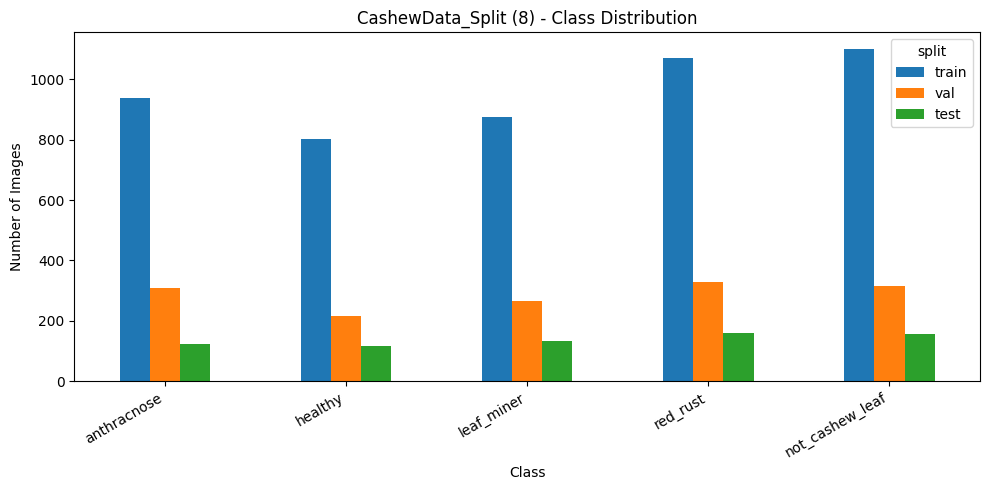

In [8]:

# ============================================================
# 07. DATASET DISTRIBUTION
# ============================================================

ax = stats_df[["train", "val", "test"]].plot(
    kind="bar",
    figsize=(10, 5)
)

ax.set_title("CashewData_Split (8) - Class Distribution")
ax.set_xlabel("Class")
ax.set_ylabel("Number of Images")

plt.xticks(rotation=30, ha="right")
plt.tight_layout()

plt.savefig(
    AGGREGATE_DIR / "class_distribution.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


In [9]:
# 08. Explicit class/file order and EXIF-aware RGB tf.data pipeline
CLASS_NAMES = EXPECTED_CLASSES
NUM_CLASSES = len(CLASS_NAMES)
AUTOTUNE = tf.data.AUTOTUNE

def split_arrays(split_name):
    df = valid_df[valid_df["split"] == split_name].copy().reset_index(drop=True)
    assert (df["label"].to_numpy() == df["class"].map(
        {name: i for i, name in enumerate(CLASS_NAMES)}).to_numpy()).all()
    return df["path"].to_numpy(), df["label"].to_numpy(dtype=np.int32), df

train_paths, train_labels, train_meta = split_arrays("train")
val_paths, val_labels, val_meta = split_arrays("val")
test_paths, test_labels, test_meta = split_arrays("test")

def _pil_rgb(path):
    with Image.open(os.fsdecode(path.numpy())) as handle:
        rgb = ImageOps.exif_transpose(handle).convert("RGB")
        return np.asarray(rgb, dtype=np.uint8)

def decode_image(path, label):
    image = tf.py_function(_pil_rgb, [path], Tout=tf.uint8)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE], method="bilinear")
    return tf.cast(image, tf.float32), tf.cast(label, tf.int32)

def make_dataset(paths, labels, seed, training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    options = tf.data.Options()
    options.experimental_deterministic = not training
    ds = ds.with_options(options)
    if training:
        ds = ds.shuffle(len(paths), seed=seed, reshuffle_each_iteration=True)
    ds = ds.map(decode_image, num_parallel_calls=AUTOTUNE, deterministic=not training)
    return ds.batch(BATCH_SIZE, drop_remainder=False).prefetch(AUTOTUNE)

print("Train/Val/Test:", len(train_paths), len(val_paths), len(test_paths))
print("Explicit class order:", list(enumerate(CLASS_NAMES)))


Train/Val/Test: 4790 1430 686
Explicit class order: [(0, 'anthracnose'), (1, 'healthy'), (2, 'leaf_miner'), (3, 'red_rust'), (4, 'not_cashew_leaf')]


## ResNet50 Caffe preprocessing and model smoke

The loader returns raw RGB float32 pixels after EXIF transpose and bilinear
resize. The model alone converts RGB to BGR and subtracts Caffe channel means.
Augmentation layers run during training only. The smoke cell checks parity
against Keras, ImageNet initialization, trainability, BN state, checkpoints,
and a safe `.keras` round trip before the five-seed loop.


In [10]:
# 09. Model builder and mandatory pipeline smoke
import tempfile
import subprocess
from PIL import ImageOps

AUGMENTATION_CONFIG = {"horizontal_flip": True, "rotation_factor": 0.08,
                       "zoom_factor": 0.10, "contrast_factor": 0.10,
                       "brightness": False}

def resnet50_preprocessing(rgb):
    bgr = keras.ops.flip(rgb, axis=-1)
    return bgr - keras.ops.convert_to_tensor(
        [103.939, 116.779, 123.68], dtype="float32")

def build_transfer_model(seed, weights="imagenet"):
    set_global_seed(seed)
    inputs = keras.Input((IMG_SIZE, IMG_SIZE, 3), name="raw_rgb_0_255")
    augmented = keras.Sequential([
        layers.RandomFlip("horizontal", seed=seed),
        layers.RandomRotation(0.08, seed=seed),
        layers.RandomZoom(0.10, seed=seed),
        layers.RandomContrast(0.10, seed=seed),
    ], name=f"train_only_augmentation_seed_{seed}")(inputs)
    x = resnet50_preprocessing(augmented)
    backbone = keras.applications.ResNet50(
        include_top=False, weights=weights,
        input_shape=(IMG_SIZE, IMG_SIZE, 3), pooling="avg")
    backbone.trainable = False
    features = backbone(x, training=False)
    x = layers.Dropout(HEAD_DROPOUT, seed=seed)(features)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax", dtype="float32",
                           name="disease_output")(x)
    return keras.Model(inputs, outputs, name=f"ResNet50_Transfer_seed_{seed}"), backbone

def set_backbone_stage(backbone, stage):
    if stage not in ("stage1", "stage2"):
        raise ValueError(stage)
    # 008 is a frozen-feature transfer ablation in both stages.
    backbone.trainable = False
    if any(layer.trainable for layer in backbone.layers):
        raise RuntimeError("Backbone must remain frozen in both stages")
    return 0

def compile_stage(model, lr):
    model.compile(optimizer=keras.optimizers.AdamW(learning_rate=lr,
                                                  weight_decay=WEIGHT_DECAY),
                  loss=keras.losses.SparseCategoricalCrossentropy(),
                  metrics=["accuracy"], steps_per_execution=1, jit_compile=False)

def save_json(path, value):
    Path(path).write_text(json.dumps(value, indent=2, ensure_ascii=False), encoding="utf-8")

def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1 << 20), b""):
            digest.update(block)
    return digest.hexdigest()

if RUN_PIPELINE_SMOKE:
    set_global_seed(SEEDS[0])  # Required when TensorFlow op determinism is enabled.
    rgb = np.zeros((2, IMG_SIZE, IMG_SIZE, 3), dtype=np.float32)
    rgb[0, 0, 0] = [255.0, 0.0, 0.0]
    rgb[0, 0, 1] = [0.0, 128.0, 255.0]
    rgb[1] = np.random.default_rng(SEEDS[0]).uniform(0, 255, rgb[1].shape)
    p = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    preprocess_model = keras.Model(p, resnet50_preprocessing(p))
    expected = keras.applications.resnet50.preprocess_input(rgb.copy())
    actual = preprocess_model(rgb, training=False).numpy()
    parity_error = float(np.max(np.abs(expected - actual)))
    if parity_error >= 1e-4 or not np.allclose(actual[0, 0, 0],
                                              [-103.939, -116.779, 131.32], atol=1e-4):
        raise AssertionError(f"ResNet50 Caffe preprocessing failed: {parity_error}")
    smoke_train = next(iter(make_dataset(train_paths, train_labels, SEEDS[0], True)))
    smoke_val = next(iter(make_dataset(val_paths, val_labels, SEEDS[0], False)))
    try:
        model, backbone = build_transfer_model(SEEDS[0], weights="imagenet")
    except Exception as exc:
        message = str(exc)
        blocked = any(token in message.lower() for token in
                      ("url fetch failure", "no such file", "download", "connection"))
        save_json(OUT_DIR / "pipeline_smoke.json", {
            "status": "BLOCKED" if blocked else "FAILED",
            "reason": "BLOCKED_PRETRAINED_WEIGHTS" if blocked else "MODEL_BUILD_FAILED",
            "error": message})
        raise RuntimeError("ImageNet ResNet50 initialization failed; see pipeline_smoke.json") from exc
    if model.output_shape != (None, NUM_CLASSES):
        raise AssertionError("Wrong model output shape")
    initial_backbone = [w.numpy().copy() for w in backbone.weights[:2]]
    stage1_params = set_backbone_stage(backbone, "stage1")
    if stage1_params != 0 or not model.trainable_weights:
        raise AssertionError("Stage 1 trainability is wrong")
    compile_stage(model, STAGE1_LR)
    model.train_on_batch(smoke_train[0][:2], smoke_train[1][:2])
    if any(not np.array_equal(a, w.numpy()) for a, w in zip(initial_backbone, backbone.weights[:2])):
        raise AssertionError("Frozen backbone changed in Stage 1")
    stage1_prob = model(smoke_val[0][:2], training=False).numpy()
    for batch in (smoke_val[0][:1], smoke_val[0][:16]):
        scores = model(batch, training=False).numpy()
        if scores.shape != (len(batch), NUM_CLASSES) or not np.isfinite(scores).all():
            raise AssertionError("Invalid softmax output")
        if not np.allclose(scores.sum(axis=1), 1.0, atol=1e-5):
            raise AssertionError("Softmax probabilities do not sum to one")
    if not np.allclose(stage1_prob, model(smoke_val[0][:2], training=False).numpy(), atol=1e-6):
        raise AssertionError("Inference path is stochastic")
    bn_layers = [layer for layer in backbone.layers if isinstance(layer, layers.BatchNormalization)]
    bn_before = [(layer.moving_mean.numpy().copy(), layer.moving_variance.numpy().copy())
                 for layer in bn_layers]
    stage2_params = set_backbone_stage(backbone, "stage2")
    if stage2_params != 0 or not model.trainable_weights:
        raise AssertionError("Stage 2 must train only the classification head")
    old_optimizer = model.optimizer
    compile_stage(model, STAGE2_LR)
    if model.optimizer is old_optimizer:
        raise AssertionError("Stage 2 reused the Stage 1 optimizer")
    model.train_on_batch(smoke_train[0][:2], smoke_train[1][:2])
    if any(not (np.array_equal(a, layer.moving_mean.numpy()) and
                np.array_equal(b, layer.moving_variance.numpy()))
           for (a, b), layer in zip(bn_before, bn_layers)):
        raise AssertionError("Backbone BatchNorm moving statistics changed")
    with tempfile.TemporaryDirectory() as temporary:
        weights_path = Path(temporary) / "smoke.weights.h5"
        model_path = Path(temporary) / "smoke.keras"
        expected_scores = model(smoke_val[0][:3], training=False).numpy()
        model.save_weights(weights_path)
        model.save(model_path)
        model.layers[-1].bias.assign_add(tf.one_hot(
            0, NUM_CLASSES, on_value=20.0, off_value=0.0,
            dtype=model.layers[-1].bias.dtype))
        if np.allclose(expected_scores, model(smoke_val[0][:3], training=False).numpy(), atol=1e-5):
            raise AssertionError("Smoke mutation did not change predictions")
        model.load_weights(weights_path)
        if not np.allclose(expected_scores, model(smoke_val[0][:3], training=False).numpy(), atol=1e-5):
            raise AssertionError("Checkpoint failed reload parity")
        restored = keras.models.load_model(model_path, compile=False, safe_mode=True)
        if not np.allclose(expected_scores, restored(smoke_val[0][:3], training=False).numpy(), atol=1e-5):
            raise AssertionError("Safe .keras reload changed predictions")
        input_path = Path(temporary) / "input.npy"
        output_path = Path(temporary) / "clean_process_output.npy"
        np.save(input_path, smoke_val[0][:3].numpy())
        clean_code = (
            "import sys,numpy as np,tensorflow as tf; from tensorflow import keras; "
            "keras.utils.set_random_seed(int(sys.argv[4])); "
            "tf.config.experimental.enable_op_determinism(); "
            "m=keras.models.load_model(sys.argv[1],compile=False,safe_mode=True); "
            "np.save(sys.argv[3],m(np.load(sys.argv[2]),training=False).numpy())"
        )
        subprocess.run([sys.executable, "-c", clean_code, str(model_path),
                        str(input_path), str(output_path), str(SEEDS[0])], check=True)
        clean_scores = np.load(output_path)
        if clean_scores.shape != expected_scores.shape or not np.isfinite(clean_scores).all():
            raise AssertionError("Clean-process .keras output has invalid shape or values")
        clean_max_abs_error = float(np.max(np.abs(expected_scores - clean_scores)))
        clean_same_top1 = bool(np.array_equal(expected_scores.argmax(axis=1),
                                              clean_scores.argmax(axis=1)))
        print("Clean-process reload max abs error:", clean_max_abs_error,
              "| same top-1:", clean_same_top1)
        # Independent TensorFlow processes can choose different GPU kernels.
        # Keep this a meaningful numerical check instead of bitwise parity.
        if not np.allclose(expected_scores, clean_scores, rtol=1e-3, atol=5e-4):
            raise AssertionError(
                f"Clean-process .keras reload differs: max_abs={clean_max_abs_error:.6g}, "
                f"same_top1={clean_same_top1}")
    save_json(OUT_DIR / "pipeline_smoke.json", {
        "status": "PASS", "preprocess_max_abs_error": parity_error,
        "stage1_backbone_trainable_params": stage1_params,
        "stage2_backbone_trainable_params": stage2_params,
        "backbone_batchnorm_layers": len(bn_layers),
        "weights_and_model_reload": "PASS", "imagenet_initialization": "PASS",
        "clean_process_max_abs_error": clean_max_abs_error,
        "clean_process_same_top1": clean_same_top1,
        "clean_process_atol": 5e-4, "clean_process_rtol": 1e-3})
    print("Pipeline smoke PASS: ImageNet, Caffe preprocessing, stages, BN, reload")
    del model, backbone, restored
    keras.backend.clear_session(); gc.collect()
else:
    print("Pipeline smoke NOT_RUN")


Global seed set to: 42
Global seed set to: 42
Clean-process reload max abs error: 0.0 | same top-1: True
Pipeline smoke PASS: ImageNet, Caffe preprocessing, stages, BN, reload


## Freeze the recipe, then train both stages

The configuration and dataset fingerprint are written before fitting. Each
seed has separate Stage 1 and Stage 2 histories and checkpoints. Stage 2
starts from the best Stage 1 weights, uses a fresh optimizer, and keeps
BatchNorm frozen. The selected seed checkpoint comes from Validation only.


In [11]:
# 09. Immutable experiment recipe
experiment_config = {
    "experiment_id": EXPERIMENT_ID, "notebook_version": NOTEBOOK_VERSION,
    "baseline_source": "partial ResNet50 Transfer-006 logs; DenseNet121-014 is a same-V08 external comparator",
    "comparison_scope": "frozen backbone versus ResNet50 Transfer-007 on the same V08; no claim until 008 is run",
    "dataset": {"name": DATASET_VERSION, "archive": DATASET_ARCHIVE_NAME,
                "archive_sha256": DATASET_ZIP_SHA256,
                "manifest_sha256": DATASET_MANIFEST_SHA256,
                "counts": EXPECTED_TOTALS, "class_names": EXPECTED_CLASSES,
                "real_filename_counts": EXPECTED_REAL_FILENAME_COUNTS},
    "seeds": SEEDS, "input": "raw RGB float32 0..255, bilinear resize 224x224",
    "model": {"backbone": "ResNet50", "weights": "imagenet",
              "include_top": False, "pooling": "avg", "head_dropout": HEAD_DROPOUT,
              "preprocessing": "inside model: RGB to BGR, subtract Caffe BGR means; no /255",
              "augmentation": AUGMENTATION_CONFIG,
              "backbone_call": "backbone(x, training=False)"},
    "selection_tolerance": 1e-6,
    "run_final_test": RUN_FINAL_TEST,
    "run_real_holdout": RUN_REAL_HOLDOUT,
    "diagnostics": {"pre_fit_random_head": True, "first_batch_metrics": True,
        "train_probe_per_class": 100, "val_train_near_candidate_report": True,
        "diagnostics_do_not_select_model": True},
    "optimizer": "AdamW", "weight_decay": WEIGHT_DECAY, "batch_size": BATCH_SIZE,
    "loss": "SparseCategoricalCrossentropy",
    "stage1": {"lr": STAGE1_LR, "max_epochs": STAGE1_EPOCHS,
               "early_patience": STAGE1_EARLY_PATIENCE,
               "reduce_patience": STAGE1_REDUCE_PATIENCE, "min_lr": STAGE1_MIN_LR,
               "trainable_backbone": "none"},
    "stage2": {"lr": STAGE2_LR, "max_epochs": STAGE2_EPOCHS,
               "early_patience": STAGE2_EARLY_PATIENCE,
               "reduce_patience": STAGE2_REDUCE_PATIENCE, "min_lr": STAGE2_MIN_LR,
               "trainable_backbone": "none; classification head only"},
    "selection_rule": "val_loss tolerance 1e-6; higher macro-F1; Stage 1 on tie",
    "deployment_rule": "val_loss tolerance 1e-6; higher macro-F1; lower seed on tie",
    "test_protocol": "enabled; evaluate only after five-seed Validation lock",
    "holdout_protocol": "enabled after lock; previously exposed 48-image four-true-class historical comparison only",
}
config_path = OUT_DIR / "experiment_config.json"
if RUN_FULL_TRAINING:
    smoke_path = OUT_DIR / "pipeline_smoke.json"
    if not smoke_path.is_file() or json.loads(smoke_path.read_text(
            encoding="utf-8")).get("status") != "PASS":
        raise RuntimeError("Pipeline smoke must PASS before five-seed training")
if config_path.exists():
    if json.loads(config_path.read_text(encoding="utf-8")) != experiment_config:
        raise ValueError("Existing EXP-008 recipe differs. Use a new experiment ID for changes.")
else:
    save_json(config_path, experiment_config)
CONFIG_SHA256 = file_sha256(config_path)
print("Frozen recipe SHA256:", CONFIG_SHA256)


Frozen recipe SHA256: 167a748a76308806849a5c7dfe9f64e903c766751ca03cd22b9cea3a084debcc


In [12]:
# 10–14. Two-stage five-seed training and Validation-only selection
class EpochAudit(tf.keras.callbacks.Callback):
    def __init__(self):
        super().__init__()
        self.rows = []
        self.current_lr = None
    def on_epoch_begin(self, epoch, logs=None):
        self.current_lr = float(self.model.optimizer.learning_rate.numpy())
        self.first_batch_accuracy = None
        self.first_batch_loss = None

    def on_train_batch_end(self, batch, logs=None):
        if batch == 0:
            self.first_batch_accuracy = float((logs or {}).get("accuracy", float("nan")))
            self.first_batch_loss = float((logs or {}).get("loss", float("nan")))
    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        self.rows.append({"epoch": epoch + 1, "accuracy": float(logs["accuracy"]),
                          "loss": float(logs["loss"]),
                          "val_accuracy": float(logs["val_accuracy"]),
                          "val_loss": float(logs["val_loss"]),
                          "learning_rate": self.current_lr,
                          "first_batch_accuracy": self.first_batch_accuracy,
                          "first_batch_loss": self.first_batch_loss})

def stage_callbacks(stage_dir, early_patience, reduce_patience, min_lr):
    audit = EpochAudit()
    checkpoint = stage_dir / "best.weights.h5"
    callbacks = [
        audit,
        keras.callbacks.ModelCheckpoint(str(checkpoint), monitor="val_loss", mode="min",
                                        save_best_only=True, save_weights_only=True, verbose=1),
        keras.callbacks.EarlyStopping(monitor="val_loss", mode="min", patience=early_patience,
                                      restore_best_weights=False, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", mode="min", factor=LR_REDUCTION_FACTOR,
                                          patience=reduce_patience, min_lr=min_lr, verbose=1),
        keras.callbacks.CSVLogger(str(stage_dir / "training_log.csv")),
        keras.callbacks.TerminateOnNaN(),
    ]
    save_json(stage_dir / "callbacks.json", {
        "monitor": "val_loss", "mode": "min",
        "early_stopping_patience": early_patience,
        "reduce_lr_factor": LR_REDUCTION_FACTOR,
        "reduce_lr_patience": reduce_patience, "min_lr": min_lr,
        "restore_best_weights": False, "checkpoint": str(checkpoint)})
    return audit, callbacks, checkpoint

def evaluate_candidate(model, val_ds, stage_dir, stage, audit, elapsed, trainable_params):
    history = pd.DataFrame(audit.rows)
    if history.empty or not np.isfinite(history[["loss", "val_loss"]].to_numpy()).all():
        raise RuntimeError(f"Invalid {stage} history")
    history.to_csv(stage_dir / "history.csv", index=False)
    best = history.sort_values(["val_loss", "epoch"], ascending=[True, True]).iloc[0]
    checkpoint = stage_dir / "best.weights.h5"
    if not checkpoint.is_file():
        raise FileNotFoundError(checkpoint)
    model.load_weights(checkpoint)
    val_loss, val_accuracy = model.evaluate(val_ds, verbose=0)
    probabilities = np.asarray(model.predict(val_ds, verbose=0))
    predicted = probabilities.argmax(axis=1)
    candidate = {
        "stage": stage, "best_epoch": int(best["epoch"]),
        "actual_epochs": len(history), "fit_seconds": float(elapsed),
        "val_loss": float(val_loss), "val_accuracy": float(val_accuracy),
        "val_macro_f1": float(f1_score(val_labels, predicted, labels=np.arange(NUM_CLASSES),
                                        average="macro", zero_division=0)),
        "checkpoint_path": str(checkpoint), "checkpoint_sha256": file_sha256(checkpoint),
        "checkpoint_size_mb": checkpoint.stat().st_size / (1024 ** 2),
        "backbone_trainable_params": trainable_params,
        "learning_rate_first": float(history.iloc[0]["learning_rate"]),
        "learning_rate_last": float(history.iloc[-1]["learning_rate"]),
    }
    if not np.isclose(candidate["val_loss"], float(best["val_loss"]), atol=1e-5):
        raise RuntimeError(f"Reloaded {stage} checkpoint differs from best val_loss epoch")
    save_json(stage_dir / "summary.json", candidate)
    return candidate

def save_selected_validation(seed, model, val_ds, seed_dir, selected):
    output = seed_dir / "validation"
    output.mkdir(exist_ok=True)
    _ = model.predict(val_ds.take(1), verbose=0)  # Warm up model tracing.
    prediction_started = time.perf_counter()
    probabilities = np.asarray(model.predict(val_ds, verbose=0))
    prediction_seconds = time.perf_counter() - prediction_started
    y_true = np.asarray(val_labels, dtype=np.int32)
    y_pred = probabilities.argmax(axis=1)
    if probabilities.shape != (len(y_true), NUM_CLASSES):
        raise ValueError("Validation predictions are not aligned to the fixed file list")
    metrics = {
        "seed": seed, "selected_stage": selected["stage"],
        "selected_epoch": selected["best_epoch"],
        "val_loss": selected["val_loss"],
        "val_accuracy": float(accuracy_score(y_true, y_pred)),
        "val_macro_precision": float(precision_score(y_true, y_pred, average="macro", zero_division=0)),
        "val_macro_recall": float(recall_score(y_true, y_pred, average="macro", zero_division=0)),
        "val_macro_f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
        "val_balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
        "prediction_seconds_including_input_pipeline": float(prediction_seconds),
        "inference_time_ms_per_image": float(1000 * prediction_seconds / len(y_true)),
        "anthracnose_recall": float(recall_score(y_true == CLASS_NAMES.index("anthracnose"),
                                                  y_pred == CLASS_NAMES.index("anthracnose"), zero_division=0)),
        "leaf_miner_recall": float(recall_score(y_true == CLASS_NAMES.index("leaf_miner"),
                                                 y_pred == CLASS_NAMES.index("leaf_miner"), zero_division=0)),
    }
    disease_ids = [CLASS_NAMES.index(name) for name in ("anthracnose", "leaf_miner", "red_rust")]
    disease_mask = np.isin(y_true, disease_ids)
    false_healthy_count = int(np.sum(disease_mask & (y_pred == CLASS_NAMES.index("healthy"))))
    metrics.update(false_healthy_count=false_healthy_count,
                   disease_count=int(disease_mask.sum()),
                   false_healthy_rate=float(false_healthy_count / disease_mask.sum()))
    probe_ds = make_dataset(train_paths[TRAIN_PROBE_INDICES],
                            train_labels[TRAIN_PROBE_INDICES], seed, training=False)
    probe_probabilities = np.asarray(model.predict(probe_ds, verbose=0))
    probe_predicted = probe_probabilities.argmax(axis=1)
    probe_true = train_labels[TRAIN_PROBE_INDICES]
    metrics.update(train_probe_size=int(len(probe_true)),
                   train_probe_accuracy=float(accuracy_score(probe_true, probe_predicted)),
                   train_probe_macro_f1=float(f1_score(probe_true, probe_predicted,
                                                      average="macro", zero_division=0)),
                   train_probe_minus_val_accuracy=float(
                       accuracy_score(probe_true, probe_predicted) - metrics["val_accuracy"]))
    save_json(output / "metrics.json", metrics)
    pd.DataFrame(classification_report(y_true, y_pred, labels=np.arange(NUM_CLASSES),
                                       target_names=CLASS_NAMES, output_dict=True,
                                       zero_division=0)).T.to_csv(output / "classification_report.csv")
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(NUM_CLASSES))
    cm_norm = confusion_matrix(y_true, y_pred, labels=np.arange(NUM_CLASSES), normalize="true")
    for matrix, suffix in ((cm, ""), (cm_norm, "_normalized")):
        pd.DataFrame(matrix, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
            output / f"confusion_matrix{suffix}.csv")
        fig, ax = plt.subplots(figsize=(8, 7), facecolor="white")
        ax.imshow(matrix, cmap=MATRIX_CMAP, vmin=0,
                  vmax=1 if suffix else max(1, matrix.max()))
        ax.set_xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=40, ha="right")
        ax.set_yticks(range(NUM_CLASSES), CLASS_NAMES)
        for row in range(NUM_CLASSES):
            for column in range(NUM_CLASSES):
                ax.text(column, row, f"{matrix[row, column]:.2f}" if suffix else str(int(matrix[row, column])),
                        ha="center", va="center", color="black")
        ax.set_xlabel("Predicted"); ax.set_ylabel("True")
        fig.tight_layout(); fig.savefig(output / f"confusion_matrix{suffix}.png", dpi=180)
        plt.close(fig)
    predictions = pd.DataFrame({
        "relative_path": val_meta["relative_path"], "split": "val",
        "is_real_filename": val_meta["is_real_filename"],
        "true_class_idx": y_true, "predicted_class_idx": y_pred,
        "true_label": [CLASS_NAMES[i] for i in y_true],
        "predicted_label": [CLASS_NAMES[i] for i in y_pred],
        "confidence": probabilities.max(axis=1), "correct": y_true == y_pred,
    })
    for index, name in enumerate(CLASS_NAMES):
        predictions[f"prob_{name}"] = probabilities[:, index]
    predictions.to_csv(output / "predictions.csv", index=False)
    predictions[~predictions["correct"]].to_csv(output / "error_cases.csv", index=False)
    return metrics

def choose_stage(stage1, stage2, tolerance=1e-6):
    delta = stage1["val_loss"] - stage2["val_loss"]
    if abs(delta) > tolerance:
        return stage1 if delta < 0 else stage2
    if abs(stage1["val_macro_f1"] - stage2["val_macro_f1"]) > 1e-12:
        return max((stage1, stage2), key=lambda row: row["val_macro_f1"])
    return stage1


# Fixed, balanced Train probe measures inference without augmentation/dropout.
# It is diagnostic only and never participates in checkpoint/seed selection.
probe_rng = np.random.default_rng(20261019)
TRAIN_PROBE_INDICES = np.sort(np.concatenate([
    probe_rng.choice(np.flatnonzero(train_labels == class_id), size=100, replace=False)
    for class_id in range(NUM_CLASSES)
]))
assert len(TRAIN_PROBE_INDICES) == 500

training_rows, validation_rows = [], []
for run_index, seed in enumerate(SEEDS if RUN_FULL_TRAINING else [], start=1):
    seed_dir = OUT_DIR / f"seed_{seed}"
    stage1_dir, stage2_dir = seed_dir / "stage1", seed_dir / "stage2"
    selected_path = seed_dir / "best.weights.h5"
    summary_path = seed_dir / "training_summary.json"
    validation_path = seed_dir / "validation" / "metrics.json"
    if all(path.is_file() for path in (selected_path, summary_path, validation_path,
                                        stage1_dir / "best.weights.h5", stage2_dir / "best.weights.h5")):
        training_rows.append(json.loads(summary_path.read_text(encoding="utf-8")))
        validation_rows.append(json.loads(validation_path.read_text(encoding="utf-8")))
        print("Reusing completed seed", seed)
        continue
    if seed_dir.exists() and any(seed_dir.rglob("*")):
        raise FileExistsError(f"Partial seed output needs review: {seed_dir}")
    for directory in (stage1_dir, stage2_dir):
        directory.mkdir(parents=True)
    print(f"SEED {run_index}/{len(SEEDS)}: {seed}")
    keras.backend.clear_session(); gc.collect(); set_global_seed(seed)
    train_ds = make_dataset(train_paths, train_labels, seed, training=True)
    val_ds = make_dataset(val_paths, val_labels, seed, training=False)
    model, backbone = build_transfer_model(seed, weights="imagenet")

    stage1_params = set_backbone_stage(backbone, "stage1")
    compile_stage(model, STAGE1_LR)
    # Epoch-zero reference: random classification head, ImageNet backbone,
    # before any EXP-008 gradient update. Never used to choose hyperparameters.
    pre_fit_probability = np.asarray(model.predict(val_ds, verbose=0))
    pre_fit_predicted = pre_fit_probability.argmax(axis=1)
    pre_fit = {"seed": seed, "images": len(val_labels),
               "accuracy": float(accuracy_score(val_labels, pre_fit_predicted)),
               "macro_f1": float(f1_score(val_labels, pre_fit_predicted,
                                           average="macro", zero_division=0)),
               "loss": float(-np.log(np.clip(pre_fit_probability[
                   np.arange(len(val_labels)), val_labels], 1e-7, 1)).mean()),
               "description": "ImageNet backbone plus random head before Stage 1"}
    save_json(seed_dir / "pre_fit_validation.json", pre_fit)
    print("Pre-fit Validation (diagnostic only):", pre_fit)
    audit1, callbacks1, _ = stage_callbacks(stage1_dir, STAGE1_EARLY_PATIENCE,
                                            STAGE1_REDUCE_PATIENCE, STAGE1_MIN_LR)
    started = time.perf_counter()
    model.fit(train_ds, validation_data=val_ds, epochs=STAGE1_EPOCHS,
              callbacks=callbacks1, verbose=1)
    stage1_seconds = time.perf_counter() - started
    stage1 = evaluate_candidate(model, val_ds, stage1_dir, "stage1", audit1,
                                stage1_seconds, stage1_params)

    # evaluate_candidate restored Stage 1 best. Stage 2 starts from these exact weights.
    stage2_params = set_backbone_stage(backbone, "stage2")
    old_optimizer = model.optimizer
    compile_stage(model, STAGE2_LR)
    if model.optimizer is old_optimizer:
        raise AssertionError("Stage 2 must have a new optimizer")
    audit2, callbacks2, _ = stage_callbacks(stage2_dir, STAGE2_EARLY_PATIENCE,
                                            STAGE2_REDUCE_PATIENCE, STAGE2_MIN_LR)
    started = time.perf_counter()
    model.fit(train_ds, validation_data=val_ds, epochs=STAGE2_EPOCHS,
              callbacks=callbacks2, verbose=1)
    stage2_seconds = time.perf_counter() - started
    stage2 = evaluate_candidate(model, val_ds, stage2_dir, "stage2", audit2,
                                stage2_seconds, stage2_params)

    selected = choose_stage(stage1, stage2)
    set_backbone_stage(backbone, selected["stage"])
    source_checkpoint = stage1_dir if selected["stage"] == "stage1" else stage2_dir
    model.load_weights(source_checkpoint / "best.weights.h5")
    selected_reloaded_loss = float(model.evaluate(val_ds, verbose=0)[0])
    if not np.isclose(selected_reloaded_loss, selected["val_loss"], atol=1e-5):
        raise RuntimeError("Selected stage checkpoint failed reload parity")
    shutil.copyfile(source_checkpoint / "best.weights.h5", selected_path)
    stage_selection = {
        "seed": seed, "selected_stage": selected["stage"],
        "selected_epoch": selected["best_epoch"], "selection_metric": "val_loss",
        "val_loss": selected["val_loss"], "val_macro_f1": selected["val_macro_f1"],
        "tie_break": "higher val_macro_f1, then Stage 1",
        "checkpoint_sha256": file_sha256(selected_path),
        "model_params": int(model.count_params()),
        "stage_candidates": {"stage1": stage1, "stage2": stage2},
    }
    save_json(seed_dir / "stage_selection.json", stage_selection)
    validation = save_selected_validation(seed, model, val_ds, seed_dir, selected)
    summary = {
        "seed": seed, "selected_stage": selected["stage"],
        "stage1_epochs": stage1["actual_epochs"], "stage2_epochs": stage2["actual_epochs"],
        "pre_fit_val_accuracy": pre_fit["accuracy"],
        "stage1_training_seconds": stage1_seconds, "stage2_training_seconds": stage2_seconds,
        "training_time_seconds": stage1_seconds + stage2_seconds,
        "stage1_backbone_trainable_params": stage1_params,
        "stage2_backbone_trainable_params": stage2_params,
        "total_parameters": int(model.count_params()),
        "selected_checkpoint_sha256": stage_selection["checkpoint_sha256"],
        "selected_checkpoint_size_mb": selected_path.stat().st_size / (1024 ** 2),
    }
    save_json(summary_path, summary)
    training_rows.append(summary); validation_rows.append(validation)
    del model, backbone, train_ds, val_ds
    keras.backend.clear_session(); gc.collect()

if RUN_FULL_TRAINING:
    training_summary_df = pd.DataFrame(training_rows)
    validation_results_df = pd.DataFrame(validation_rows)
    if training_summary_df["seed"].tolist() != SEEDS or validation_results_df["seed"].tolist() != SEEDS:
        raise RuntimeError("All five seeds must complete before aggregation")
    training_summary_df.to_csv(AGGREGATE_DIR / "training_summary_5seeds.csv", index=False)
    validation_results_df.to_csv(AGGREGATE_DIR / "validation_results_5seeds.csv", index=False)
else:
    training_summary_df = pd.read_csv(AGGREGATE_DIR / "training_summary_5seeds.csv")
    validation_results_df = pd.read_csv(AGGREGATE_DIR / "validation_results_5seeds.csv")
    if training_summary_df["seed"].tolist() != SEEDS or validation_results_df["seed"].tolist() != SEEDS:
        raise ValueError("Saved five-seed order does not match the protocol")

def choose_deployment_seed(rows, tolerance=1e-6):
    candidates = rows.to_dict("records")
    lowest = min(float(row["val_loss"]) for row in candidates)
    near = [row for row in candidates if float(row["val_loss"]) <= lowest + tolerance]
    return int(sorted(near, key=lambda row: (-float(row["val_macro_f1"]), int(row["seed"])))[0]["seed"])

deployment_seed = choose_deployment_seed(validation_results_df)
selection_lock = {
    "experiment_id": EXPERIMENT_ID, "config_sha256": CONFIG_SHA256,
    "dataset_sha256": DATASET_ZIP_SHA256,
    "dataset_manifest_sha256": DATASET_MANIFEST_SHA256,
    "class_names": CLASS_NAMES, "seeds": SEEDS,
    "selection_rule": experiment_config["selection_rule"],
    "deployment_rule": experiment_config["deployment_rule"],
    "deployment_seed": deployment_seed,
    "validation_sha256": file_sha256(AGGREGATE_DIR / "validation_results_5seeds.csv"),
    "per_seed_selection": {str(seed): json.loads(
        (OUT_DIR / f"seed_{seed}" / "stage_selection.json").read_text(encoding="utf-8"))
        for seed in SEEDS},
    "selected_checkpoint_sha256": {
        str(seed): file_sha256(OUT_DIR / f"seed_{seed}" / "best.weights.h5") for seed in SEEDS
    },
}
lock_path = OUT_DIR / "validation_selection_lock.json"
if lock_path.exists():
    previous_lock = json.loads(lock_path.read_text(encoding="utf-8"))
    selection_lock["locked_at"] = previous_lock.get("locked_at")
    if previous_lock != selection_lock:
        raise ValueError("Validation lock changed; do not run Test or holdout")
else:
    selection_lock["locked_at"] = datetime.now().astimezone().isoformat()
    save_json(lock_path, selection_lock)
print("Validation-only deployment seed:", deployment_seed)


SEED 1/5: 42
Global seed set to: 42
Global seed set to: 42
Pre-fit Validation (diagnostic only): {'seed': 42, 'images': 1430, 'accuracy': 0.23916083916083916, 'macro_f1': 0.13918959554036692, 'loss': 2.204252243041992, 'description': 'ImageNet backbone plus random head before Stage 1'}
Epoch 1/12
299/300 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.5387 - loss: 1.1923
Epoch 1: val_loss improved from None to 0.32085, saving model to /content/drive/MyDrive/Cashew_Leaf_model_result/training_results/current_dataset/EXP-RESNET50-TRANSFER-5SEEDS-008/seed_42/stage1/best.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/Cashew_Leaf_model_result/training_results/current_dataset/EXP-RESNET50-TRANSFER-5SEEDS-008/seed_42/stage1/best.weights.h5
300/300 ━━━━━━━━━━━━━━━━━━━━ 26s 78ms/step - accuracy: 0.7008 - loss: 0.7953 - val_accuracy: 0.8895 - val_loss: 0.3209 - learning_rate: 3.0000e-04
Epoch 2/12
299/300 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.8726 - loss: 0.3702
Ep

In [13]:
# 15–17. Validation tables, real_ subgroup, and five-seed panels
summary_columns = ["val_accuracy", "train_probe_accuracy", "train_probe_minus_val_accuracy", "val_macro_precision", "val_macro_recall",
                   "val_macro_f1", "val_balanced_accuracy", "anthracnose_recall",
                   "leaf_miner_recall", "false_healthy_rate"]
summary_rows = []
for metric in summary_columns:
    values = validation_results_df[metric].astype(float)
    summary_rows.append({"metric": metric, "mean": values.mean(),
                         "std": values.std(ddof=1),
                         "report": f"{100*values.mean():.2f} ± {100*values.std(ddof=1):.2f}%"})
inference_ms = validation_results_df["inference_time_ms_per_image"].astype(float)
summary_rows.append({"metric": "inference_time_ms_per_image",
                     "mean": inference_ms.mean(), "std": inference_ms.std(ddof=1),
                     "report": f"{inference_ms.mean():.2f} ± {inference_ms.std(ddof=1):.2f} ms"})
pd.DataFrame(summary_rows).to_csv(AGGREGATE_DIR / "validation_mean_std_summary.csv", index=False)
training_time_columns = ["stage1_training_seconds", "stage2_training_seconds", "training_time_seconds"]
pd.DataFrame([{"metric": column,
               "mean_seconds": training_summary_df[column].mean(),
               "std_seconds": training_summary_df[column].std(ddof=1),
               "total_seconds": training_summary_df[column].sum()}
              for column in training_time_columns]).to_csv(
    AGGREGATE_DIR / "training_time_mean_std_summary.csv", index=False)

real_rows, per_class_rows = [], []
for seed in SEEDS:
    val_dir = OUT_DIR / f"seed_{seed}" / "validation"
    predictions = pd.read_csv(val_dir / "predictions.csv")
    if len(predictions) != len(val_labels):
        raise RuntimeError(f"Seed {seed} Validation rows changed")
    for group, group_df in (("real_filename", predictions[predictions["is_real_filename"]]),
                            ("other_filename", predictions[~predictions["is_real_filename"]])):
        real_rows.append({"seed": seed, "group": group, "correct": int(group_df["correct"].sum()),
                          "total": len(group_df),
                          "accuracy": float(group_df["correct"].mean())})
    report = pd.read_csv(val_dir / "classification_report.csv", index_col=0)
    for class_name in CLASS_NAMES:
        per_class_rows.append({"seed": seed, "class": class_name,
                               "precision": report.loc[class_name, "precision"],
                               "recall": report.loc[class_name, "recall"],
                               "f1": report.loc[class_name, "f1-score"],
                               "support": report.loc[class_name, "support"]})
real_validation_df = pd.DataFrame(real_rows)
for seed in SEEDS:
    row = real_validation_df[(real_validation_df["seed"] == seed) &
                             (real_validation_df["group"] == "real_filename")].iloc[0]
    if int(row["total"]) != EXPECTED_REAL_FILENAME_COUNTS["val"]:
        raise ValueError("The 35 real_ Validation filenames changed")
real_validation_df.to_csv(AGGREGATE_DIR / "real_validation_by_seed.csv", index=False)
pd.DataFrame(per_class_rows).to_csv(AGGREGATE_DIR / "per_class_validation_by_seed.csv", index=False)
pd.DataFrame(per_class_rows).groupby("class")[["precision", "recall", "f1"]].agg(
    ["mean", "std"]).to_csv(AGGREGATE_DIR / "per_class_validation_mean_std.csv")

histories = {}
for seed in SEEDS:
    histories[seed] = (
        pd.read_csv(OUT_DIR / f"seed_{seed}" / "stage1" / "history.csv"),
        pd.read_csv(OUT_DIR / f"seed_{seed}" / "stage2" / "history.csv"),
    )
fig, axes = plt.subplots(2, len(SEEDS), figsize=(28, 10), sharey="row")
for column, seed in enumerate(SEEDS):
    stage1, stage2 = histories[seed]
    boundary = len(stage1)
    for row, metric in enumerate(("accuracy", "loss")):
        ax = axes[row, column]
        for stage_df, offset, stage_name in ((stage1, 0, "Stage 1"), (stage2, boundary, "Stage 2")):
            epoch = stage_df["epoch"] + offset
            ax.plot(epoch, stage_df[metric], color="#2563eb", alpha=0.75,
                    label=f"{stage_name} Train" if row == 0 else None)
            ax.plot(epoch, stage_df[f"val_{metric}"], color="#ea580c", alpha=0.9,
                    label=f"{stage_name} Validation" if row == 0 else None)
            lr = stage_df["learning_rate"].to_numpy()
            reduced = np.flatnonzero(lr[1:] < lr[:-1]) + 1
            for index in reduced:
                ax.axvline(float(epoch.iloc[index]), color="#16a34a", alpha=0.35, linestyle=":")
        ax.axvline(boundary + 0.5, color="black", linestyle="--", alpha=0.8)
        ax.set_xlabel("Combined epoch"); ax.grid(alpha=0.25)
        if column == 0:
            ax.set_ylabel(metric.title())
    axes[0, column].set_title(f"Seed {seed}")
axes[0, 0].legend(fontsize=8)
fig.suptitle("Stage boundary: dashed; learning-rate reductions: dotted green")
fig.tight_layout()
fig.savefig(PANEL_DIR / "training_curves_5seeds_panel.png", dpi=190, bbox_inches="tight")
plt.close(fig)

for normalized, suffix in ((False, ""), (True, "_normalized")):
    fig, axes = plt.subplots(1, len(SEEDS), figsize=(28, 5.5), facecolor="white")
    for column, seed in enumerate(SEEDS):
        matrix = pd.read_csv(OUT_DIR / f"seed_{seed}" / "validation" /
                             f"confusion_matrix{suffix}.csv", index_col=0).to_numpy()
        ax = axes[column]
        ax.imshow(matrix, cmap=MATRIX_CMAP, vmin=0,
                  vmax=1 if normalized else max(1, matrix.max()))
        ax.set_title(f"Seed {seed}")
        ax.set_xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=45, ha="right")
        ax.set_yticks(range(NUM_CLASSES))
        ax.set_yticklabels(CLASS_NAMES if column == 0 else [])
        for row in range(NUM_CLASSES):
            for col in range(NUM_CLASSES):
                ax.text(col, row, f"{matrix[row, col]:.2f}" if normalized else str(int(matrix[row, col])),
                        ha="center", va="center", color="black", fontsize=8)
        ax.set_xlabel("Predicted")
    axes[0].set_ylabel("True")
    fig.tight_layout()
    fig.savefig(PANEL_DIR / f"validation_confusion_matrices{suffix}_5seeds_panel.png",
                dpi=190, bbox_inches="tight")
    plt.close(fig)
print("Validation summary:")
display(pd.DataFrame(summary_rows))
print("Validation real_ filename subgroup:")
display(real_validation_df)

# The 35 real_ filenames are a proxy subgroup, with per-class diagnostics.
real_class_rows = []
for seed in SEEDS:
    predictions = pd.read_csv(OUT_DIR / f"seed_{seed}" / "validation" / "predictions.csv")
    real_only = predictions[predictions["is_real_filename"]]
    for class_name, group in real_only.groupby("true_label"):
        real_class_rows.append({"seed": seed, "class": class_name,
                                "correct": int(group["correct"].sum()),
                                "total": len(group), "accuracy": float(group["correct"].mean())})
pd.DataFrame(real_class_rows).to_csv(AGGREGATE_DIR / "real_validation_by_class_seed.csv", index=False)

# Repeated confusion and confidence diagnostics; descriptive, never tuning.
all_errors = []
for seed in SEEDS:
    predictions = pd.read_csv(OUT_DIR / f"seed_{seed}" / "validation" / "predictions.csv")
    for _, row in predictions[~predictions["correct"]].iterrows():
        all_errors.append({"seed": seed, "relative_path": row["relative_path"],
                           "true_label": row["true_label"],
                           "predicted_label": row["predicted_label"],
                           "confidence": row["confidence"]})
pd.DataFrame(all_errors).to_csv(AGGREGATE_DIR / "validation_errors_all_seeds.csv", index=False)
if all_errors:
    recurrent = pd.DataFrame(all_errors).groupby("relative_path").agg(
        error_seed_count=("seed", "nunique"), true_label=("true_label", "first"),
        max_wrong_confidence=("confidence", "max")).reset_index().sort_values(
            ["error_seed_count", "max_wrong_confidence"], ascending=False)
    recurrent.to_csv(AGGREGATE_DIR / "recurrent_validation_errors.csv", index=False)
    pd.DataFrame(all_errors).sort_values("confidence", ascending=False).head(50).to_csv(
        AGGREGATE_DIR / "top_confident_wrong_validation.csv", index=False)
low_correct = []
for seed in SEEDS:
    predictions = pd.read_csv(OUT_DIR / f"seed_{seed}" / "validation" / "predictions.csv")
    correct = predictions[predictions["correct"]].nsmallest(20, "confidence")
    low_correct.append(correct.assign(seed=seed))
pd.concat(low_correct).to_csv(AGGREGATE_DIR / "low_confident_correct_validation.csv", index=False)

# Potential train-to-Validation near matches are descriptive candidates,
# not confirmed duplicates; never remove images or use this to rank seeds.
candidate_val_paths = set()
for _, pair in near_df.iterrows():
    if {pair["a_split"], pair["b_split"]} == {"train", "val"}:
        candidate_val_paths.add(pair["a"] if pair["a_split"] == "val" else pair["b"])
candidate_rows = []
for seed in SEEDS:
    predictions = pd.read_csv(OUT_DIR / f"seed_{seed}" / "validation" / "predictions.csv")
    mask = predictions["relative_path"].isin(candidate_val_paths)
    for group, selected in (("phash_candidate", mask), ("other_val", ~mask)):
        part = predictions[selected]
        candidate_rows.append({"seed": seed, "group": group, "correct": int(part["correct"].sum()),
                               "total": len(part), "accuracy": float(part["correct"].mean())})
pd.DataFrame(candidate_rows).to_csv(
    AGGREGATE_DIR / "near_candidate_validation_by_seed.csv", index=False)
save_json(AGGREGATE_DIR / "near_candidate_scope.json", {
    "val_train_candidate_paths": sorted(candidate_val_paths),
    "candidate_count": len(candidate_val_paths),
    "meaning": "pHash screening candidates only; no automatic leakage claim or split change"})

overfit_rows = []
for seed in SEEDS:
    stage1, stage2 = histories[seed]
    best = stage2.loc[stage2["val_loss"].idxmin()]
    last = stage2.iloc[-1]
    overfit_rows.append({"seed": seed, "stage2_best_epoch": int(best["epoch"]),
                         "stage2_best_val_loss": float(best["val_loss"]),
                         "stage2_last_val_loss": float(last["val_loss"]),
                         "stage2_val_loss_rebound": float(last["val_loss"] - best["val_loss"]),
                         "stage2_last_online_train_accuracy": float(last["accuracy"]),
                         "stage2_last_val_accuracy": float(last["val_accuracy"]),
                         "online_train_minus_val_accuracy": float(
                             last["accuracy"] - last["val_accuracy"])})
pd.DataFrame(overfit_rows).to_csv(AGGREGATE_DIR / "overfit_diagnostics_by_seed.csv", index=False)


Validation summary:


,metric,mean,std,report
0,val_accuracy,0.950909,0.002178,95.09 ± 0.22%
1,train_probe_accuracy,0.970800,0.004604,97.08 ± 0.46%
2,train_probe_minus_val_accuracy,0.019891,0.003206,1.99 ± 0.32%
3,val_macro_precision,0.948793,0.001747,94.88 ± 0.17%
4,val_macro_recall,0.949589,0.003099,94.96 ± 0.31%
5,val_macro_f1,0.949101,0.002349,94.91 ± 0.23%
6,val_balanced_accuracy,0.949589,0.003099,94.96 ± 0.31%
7,anthracnose_recall,0.905844,0.011706,90.58 ± 1.17%
8,leaf_miner_recall,0.918182,0.012157,91.82 ± 1.22%
9,false_healthy_rate,0.013333,0.001361,1.33 ± 0.14%


Validation real_ filename subgroup:


,seed,group,correct,total,accuracy
0,42,real_filename,24,35,0.685714
1,42,other_filename,1333,1395,0.955556
2,123,real_filename,24,35,0.685714
3,123,other_filename,1333,1395,0.955556
4,2026,real_filename,25,35,0.714286
5,2026,other_filename,1337,1395,0.958423
6,3407,real_filename,26,35,0.742857
7,3407,other_filename,1338,1395,0.959140
8,7777,real_filename,26,35,0.742857
9,7777,other_filename,1333,1395,0.955556


## Final Test after the Validation lock

`RUN_FINAL_TEST=True` is enabled. This section asserts the saved config,
all five selected checkpoint hashes, and the fixed Validation selection lock
before opening Test. Test outcomes cannot change the selected seed or stage.


In [14]:
# 18. Guarded Final Test
def assert_selection_lock():
    saved = json.loads((OUT_DIR / "validation_selection_lock.json").read_text(encoding="utf-8"))
    if saved != selection_lock or saved["config_sha256"] != file_sha256(config_path):
        raise ValueError("Frozen Validation/config lock changed")
    for seed in SEEDS:
        actual = file_sha256(OUT_DIR / f"seed_{seed}" / "best.weights.h5")
        if actual != saved["selected_checkpoint_sha256"][str(seed)]:
            raise ValueError(f"Seed {seed} checkpoint changed after Validation lock")
    return saved

def load_selected_model(seed):
    # weights=None is only for reconstructing architecture before immediately
    # restoring the EXP-008 trained checkpoint. Training always uses ImageNet.
    model, backbone = build_transfer_model(seed, weights=None)
    selected = json.loads((OUT_DIR / f"seed_{seed}" / "stage_selection.json").read_text(
        encoding="utf-8"))
    set_backbone_stage(backbone, selected["selected_stage"])
    model.load_weights(OUT_DIR / f"seed_{seed}" / "best.weights.h5")
    return model

if RUN_FINAL_TEST:
    assert_selection_lock()
    test_ds = make_dataset(test_paths, test_labels, SEEDS[0], training=False)
    test_rows = []
    for seed in SEEDS:
        keras.backend.clear_session(); gc.collect()
        model = load_selected_model(seed)
        output = OUT_DIR / f"seed_{seed}" / "test"
        output.mkdir(exist_ok=True)
        _ = model.predict(test_ds.take(1), verbose=0)  # Warm up tracing.
        started = time.perf_counter()
        probability = np.asarray(model.predict(test_ds, verbose=0))
        elapsed = time.perf_counter() - started
        y_true = np.asarray(test_labels, dtype=np.int32)
        y_pred = probability.argmax(axis=1)
        if probability.shape != (len(y_true), NUM_CLASSES):
            raise RuntimeError("Final Test prediction count mismatch")
        test_row = {
            "seed": seed, "images": len(y_true),
            "loss": float(-np.log(np.clip(probability[np.arange(len(y_true)), y_true], 1e-7, 1)).mean()),
            "accuracy": float(accuracy_score(y_true, y_pred)),
            "macro_precision": float(precision_score(y_true, y_pred, average="macro", zero_division=0)),
            "macro_recall": float(recall_score(y_true, y_pred, average="macro", zero_division=0)),
            "macro_f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
            "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
            "prediction_seconds_including_input_pipeline": elapsed,
            "inference_time_ms_per_image": 1000 * elapsed / len(y_true),
        }
        for group_name, mask in (("real_filename", test_meta["is_real_filename"].to_numpy(dtype=bool)),
                                 ("other_filename", ~test_meta["is_real_filename"].to_numpy(dtype=bool))):
            test_row[f"{group_name}_correct"] = int((y_true[mask] == y_pred[mask]).sum())
            test_row[f"{group_name}_total"] = int(mask.sum())
            test_row[f"{group_name}_accuracy"] = float(accuracy_score(y_true[mask], y_pred[mask]))
        save_json(output / "metrics.json", test_row)
        pd.DataFrame(classification_report(y_true, y_pred, labels=np.arange(NUM_CLASSES),
                                           target_names=CLASS_NAMES, output_dict=True,
                                           zero_division=0)).T.to_csv(output / "classification_report.csv")
        predictions = pd.DataFrame({"relative_path": test_meta["relative_path"], "split": "test",
                                    "true_class_idx": y_true, "predicted_class_idx": y_pred,
                                    "is_real_filename": test_meta["is_real_filename"],
                                    "true_label": [CLASS_NAMES[i] for i in y_true],
                                    "predicted_label": [CLASS_NAMES[i] for i in y_pred],
                                    "confidence": probability.max(axis=1),
                                    "correct": y_true == y_pred})
        for index, name in enumerate(CLASS_NAMES):
            predictions[f"prob_{name}"] = probability[:, index]
        predictions.to_csv(output / "predictions.csv", index=False)
        predictions[~predictions["correct"]].to_csv(output / "error_cases.csv", index=False)
        cm = confusion_matrix(y_true, y_pred, labels=np.arange(NUM_CLASSES))
        for normalized, suffix in ((False, ""), (True, "_normalized")):
            matrix = confusion_matrix(y_true, y_pred, labels=np.arange(NUM_CLASSES),
                                      normalize="true" if normalized else None)
            pd.DataFrame(matrix, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
                output / f"confusion_matrix{suffix}.csv")
        test_rows.append(test_row)
        del model
    test_results_df = pd.DataFrame(test_rows)
    test_results_df.to_csv(AGGREGATE_DIR / "test_results_5seeds.csv", index=False)
    pd.DataFrame([{"metric": col, "mean": test_results_df[col].mean(),
                   "std": test_results_df[col].std(ddof=1)}
                  for col in ("accuracy", "macro_precision", "macro_recall", "macro_f1",
                              "balanced_accuracy", "inference_time_ms_per_image")]).to_csv(
        AGGREGATE_DIR / "test_mean_std_summary.csv", index=False)
    for normalized, suffix in ((False, ""), (True, "_normalized")):
        fig, axes = plt.subplots(1, len(SEEDS), figsize=(28, 5.5), facecolor="white")
        for column, seed in enumerate(SEEDS):
            matrix = pd.read_csv(OUT_DIR / f"seed_{seed}" / "test" /
                                 f"confusion_matrix{suffix}.csv", index_col=0).to_numpy()
            ax = axes[column]
            ax.imshow(matrix, cmap=MATRIX_CMAP, vmin=0,
                      vmax=1 if normalized else max(1, matrix.max()))
            ax.set_title(f"Seed {seed}")
            ax.set_xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=45, ha="right")
            ax.set_yticks(range(NUM_CLASSES))
            ax.set_yticklabels(CLASS_NAMES if column == 0 else [])
            for row in range(NUM_CLASSES):
                for col in range(NUM_CLASSES):
                    ax.text(col, row, f"{matrix[row, col]:.2f}" if normalized else str(int(matrix[row, col])),
                            ha="center", va="center", color="black", fontsize=8)
            ax.set_xlabel("Predicted")
        axes[0].set_ylabel("True")
        fig.tight_layout()
        fig.savefig(PANEL_DIR / f"test_confusion_matrices{suffix}_5seeds_panel.png",
                    dpi=190, bbox_inches="tight")
        plt.close(fig)
    display(test_results_df)
else:
    print("Final Test PENDING (RUN_FINAL_TEST=False)")


Global seed set to: 42
Global seed set to: 123
Global seed set to: 2026
Global seed set to: 3407
Global seed set to: 7777


,seed,images,loss,accuracy,macro_precision,macro_recall,macro_f1,balanced_accuracy,prediction_seconds_including_input_pipeline,inference_time_ms_per_image,real_filename_correct,real_filename_total,real_filename_accuracy,other_filename_correct,other_filename_total,other_filename_accuracy
0,42,686,0.182600,0.934402,0.930064,0.929291,0.929587,0.929291,3.349289,4.882346,26,28,0.928571,615,658,0.934650
1,123,686,0.192065,0.931487,0.926180,0.925639,0.925874,0.925639,3.322434,4.843199,27,28,0.964286,612,658,0.930091
2,2026,686,0.182252,0.932945,0.928320,0.927099,0.927655,0.927099,3.303653,4.815820,26,28,0.928571,614,658,0.933131
3,3407,686,0.183379,0.928571,0.924656,0.923234,0.923540,0.923234,3.275517,4.774806,24,28,0.857143,613,658,0.931611
4,7777,686,0.185181,0.934402,0.929656,0.929222,0.929223,0.929222,3.345284,4.876507,26,28,0.928571,615,658,0.934650


## Historical real holdout after the Validation lock

`RUN_REAL_HOLDOUT=True` is enabled. The source archive contains 49 images;
one byte-identical V08 Test image is excluded, leaving 48 scored images from
four true classes. This set has been examined previously and is suitable only
for historical comparison. A fresh independent field set remains `NOT_RUN`.


In [15]:
"""Historical external classification evaluation embedded in EXP-008.

This file has no training code. Holdout labels never select checkpoints or seeds.
"""

import hashlib
import json
import os
import stat
import time
import zipfile
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from PIL import Image
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.metrics import f1_score, precision_score, recall_score


REAL_HOLDOUT_HELPER_VERSION = "008.1"
REAL_HOLDOUT_CMAP = LinearSegmentedColormap.from_list(
    "real_holdout_readable_blues", ["#ffffff", "#dbeafe", "#93c5fd"]
)


def holdout_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest().upper()


def resolve_holdout_archive(archive_name, override=None):
    if override is not None:
        candidate = Path(override)
        if not candidate.is_file():
            raise FileNotFoundError(candidate)
        return candidate
    if Path("/content/drive/MyDrive").is_dir():
        candidate = Path("/content/drive/MyDrive/Cashew_Leaf_model_result/Dataset") / archive_name
        if candidate.is_file():
            return candidate
    if os.name == "nt":
        candidate = Path(r"D:\Study\KhoaLuanTotNghiep\Dataset") / archive_name
        if candidate.is_file():
            return candidate
    if Path("/kaggle/input").is_dir():
        candidates = sorted(Path("/kaggle/input").rglob(archive_name))
        if len(candidates) == 1:
            return candidates[0]
    raise FileNotFoundError(
        f"Cannot uniquely locate {archive_name}. Set REAL_HOLDOUT_ARCHIVE_OVERRIDE "
        "to the mounted ZIP path; on Colab add the supplied Dataset folder to My Drive."
    )


def prepare_real_holdout(archive_path, extraction_dir, class_names, expected_sha256,
                         expected_counts, reference_rows, audit_dir):
    """Verify the frozen archive, labels, decoding and byte overlap with Split (8).

    reference_rows: dictionaries with path/split and optional existing sha256.
    Exact-byte checking does not establish independence of near-duplicate photos.
    """
    archive_path, extraction_dir, audit_dir = map(Path, (archive_path, extraction_dir, audit_dir))
    actual_hash = holdout_sha256(archive_path)
    if actual_hash != expected_sha256.upper():
        raise ValueError(f"Holdout archive changed: {actual_hash}; expected {expected_sha256}.")
    marker = extraction_dir / ".archive_sha256"
    if extraction_dir.exists():
        if not marker.is_file() or marker.read_text(encoding="utf-8").strip() != actual_hash:
            raise FileExistsError(f"Unverified extraction: {extraction_dir}; choose a new directory.")
    else:
        with zipfile.ZipFile(archive_path) as archive:
            resolved_root = extraction_dir.resolve()
            for member in archive.infolist():
                target = (extraction_dir / member.filename.replace("\\", "/")).resolve()
                is_symlink = stat.S_ISLNK(member.external_attr >> 16)
                if is_symlink or (target != resolved_root and resolved_root not in target.parents):
                    raise ValueError(f"Unsafe ZIP member: {member.filename}")
            extraction_dir.mkdir(parents=True)
            archive.extractall(extraction_dir)
        marker.write_text(actual_hash, encoding="utf-8")

    dataset_root = extraction_dir / "RL_Cashew_holdout"
    if not dataset_root.is_dir():
        raise FileNotFoundError(dataset_root)
    found_classes = sorted(p.name for p in dataset_root.iterdir() if p.is_dir())
    if found_classes != sorted(expected_counts) or not set(found_classes).issubset(class_names):
        raise ValueError(f"Unexpected holdout class folders: {found_classes}")
    rows = []
    for label, name in enumerate(class_names):
        class_dir = dataset_root / name
        files = sorted(p for p in class_dir.rglob("*") if p.is_file()) if class_dir.is_dir() else []
        if len(files) != expected_counts.get(name, 0):
            raise ValueError(f"Unexpected holdout count for {name}: {len(files)}")
        for image_path in files:
            if image_path.suffix.lower() not in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}:
                raise ValueError(f"Unsupported holdout image: {image_path}")
            with Image.open(image_path) as image:
                image.verify()
            with Image.open(image_path) as image:
                image.convert("RGB").load()
            rows.append({"path": str(image_path), "relative_path": image_path.relative_to(dataset_root).as_posix(),
                         "class": name, "label": label, "sha256": holdout_sha256(image_path)})
    manifest = pd.DataFrame(rows)
    if manifest.empty or manifest["sha256"].duplicated().any():
        raise ValueError("Holdout is empty or contains duplicate image bytes.")
    # A marker alone is insufficient: verify cached extraction bytes against the ZIP.
    with zipfile.ZipFile(archive_path) as frozen_archive:
        for row in rows:
            digest = hashlib.sha256()
            with frozen_archive.open("RL_Cashew_holdout/" + row["relative_path"]) as stream:
                for block in iter(lambda: stream.read(1024 * 1024), b""):
                    digest.update(block)
            if digest.hexdigest().upper() != row["sha256"]:
                raise ValueError(f"Cached holdout extraction changed: {row['relative_path']}")
    audit_dir.mkdir(parents=True, exist_ok=True)
    manifest.to_csv(audit_dir / "archive_dataset_manifest.csv", index=False)

    references = list(reference_rows)
    if not references or not {"train", "val", "test"}.issubset({r["split"] for r in references}):
        raise ValueError("Overlap audit needs the full train/val/test Split (8) reference manifest.")
    holdout_hashes = set(manifest["sha256"])
    holdout_path_by_hash = dict(zip(manifest["sha256"], manifest["relative_path"]))
    overlaps = []
    reference_digest = hashlib.sha256()
    for row in references:
        digest = row.get("sha256") or holdout_sha256(row["path"])
        digest = digest.upper()
        identity = row.get("relative_path", str(row["path"]))
        reference_digest.update(f"{row['split']}\0{identity}\0{digest}\n".encode("utf-8"))
        if digest in holdout_hashes:
            overlaps.append({"reference_path": str(row["path"]), "split": row["split"],
                             "holdout_relative_path": holdout_path_by_hash[digest],
                             "sha256": digest})
    # One known Test duplicate is excluded from scoring, not concealed.
    expected_overlap = {("test", "red_rust/IMG_3244.jpg")}
    observed_overlap = {(row["split"], row["holdout_relative_path"]) for row in overlaps}
    if observed_overlap != expected_overlap:
        raise ValueError(f"Unexpected holdout/Split (8) byte overlaps: {overlaps}")
    evaluated_manifest = manifest[~manifest["sha256"].isin(
        {row["sha256"] for row in overlaps}
    )].reset_index(drop=True)
    evaluated_manifest.to_csv(audit_dir / "dataset_manifest.csv", index=False)
    pd.DataFrame(overlaps).to_csv(audit_dir / "excluded_overlap_images.csv", index=False)
    present = [name for name in class_names if expected_counts.get(name, 0) > 0]
    audit = {"archive_sha256": actual_hash, "archive_name": archive_path.name,
             "archive_manifest_sha256": hashlib.sha256(manifest[["relative_path", "class", "label", "sha256"]]
                  .to_csv(index=False).encode()).hexdigest(),
              "manifest_sha256": hashlib.sha256(evaluated_manifest[["relative_path", "class", "label", "sha256"]]
                 .to_csv(index=False).encode()).hexdigest(),
             "counts": {name: expected_counts.get(name, 0) for name in class_names},
             "images": len(evaluated_manifest), "archive_images": len(manifest),
              "excluded_overlap_images": len(overlaps),
              "evaluated_counts": evaluated_manifest["class"].value_counts().to_dict(),
              "present_classes": present,
             "unsupported_classes": [name for name in class_names if name not in present],
             "reference_images_checked": len(references), "reference_fingerprint": reference_digest.hexdigest(),
             "byte_overlap_count": len(overlaps), "byte_overlaps": overlaps,
             "limitation": "Byte audit only; near-duplicate photos and shared trees/sessions need a separate audit."}
    (audit_dir / "dataset_audit.json").write_text(json.dumps(audit, indent=2), encoding="utf-8")
    print("Real holdout:", len(evaluated_manifest), "evaluated of", len(manifest),
          "archive images; excluded exact Test duplicate:", overlaps)
    print("Present classes:", present)
    print("Not evaluated (no true examples):", audit["unsupported_classes"])
    return evaluated_manifest, audit


def save_real_holdout_seed(manifest, probabilities, class_names, output_dir):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    probabilities = np.asarray(probabilities, dtype=np.float64)
    if probabilities.shape != (len(manifest), len(class_names)) or not np.isfinite(probabilities).all():
        raise ValueError("Holdout predictions have invalid shape or non-finite values.")
    if (probabilities < 0).any() or not np.allclose(probabilities.sum(axis=1), 1, atol=1e-5):
        raise ValueError("Holdout evaluator expects probabilities, not logits.")
    y_true = manifest["label"].to_numpy(dtype=np.int32)
    y_pred = probabilities.argmax(axis=1)
    present_ids = sorted(set(y_true.tolist()))
    all_ids = list(range(len(class_names)))
    result = {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_precision_present_classes": float(precision_score(y_true, y_pred, labels=present_ids, average="macro", zero_division=0)),
        "macro_recall_present_classes": float(recall_score(y_true, y_pred, labels=present_ids, average="macro", zero_division=0)),
        "macro_f1_present_classes": float(f1_score(y_true, y_pred, labels=present_ids, average="macro", zero_division=0)),
        "balanced_accuracy_present_classes": float(recall_score(y_true, y_pred, labels=present_ids, average="macro", zero_division=0)),
        "images": len(manifest), "macro_class_count": len(present_ids),
    }
    report = pd.DataFrame(classification_report(y_true, y_pred, labels=all_ids,
        target_names=class_names, output_dict=True, zero_division=0)).transpose()
    per_class = report.loc[class_names, ["precision", "recall", "f1-score", "support"]].copy()
    per_class["evaluated"] = per_class["support"] > 0
    # No evidence for unsupported true classes: don't present placeholder zeros as performance.
    per_class.loc[~per_class["evaluated"], ["precision", "recall", "f1-score"]] = np.nan
    per_class.to_csv(output_dir / "per_class_metrics.csv", index_label="class")
    readable_report = per_class.copy()
    readable_report["scope"] = np.where(readable_report["evaluated"], "true class present", "not evaluated: zero true support")
    readable_report.loc["macro avg (present classes)"] = [
        result["macro_precision_present_classes"], result["macro_recall_present_classes"],
        result["macro_f1_present_classes"], len(manifest), True,
        f"{len(present_ids)} supported true classes only",
    ]
    readable_report.loc["weighted avg"] = [
        report.loc["weighted avg", "precision"], report.loc["weighted avg", "recall"],
        report.loc["weighted avg", "f1-score"], len(manifest), True, "weighted by true support",
    ]
    readable_report.to_csv(output_dir / "classification_report.csv", index_label="class")
    predictions = manifest[["relative_path", "class", "label"]].copy()
    predictions["predicted_label"] = y_pred
    predictions["predicted_class"] = [class_names[i] for i in y_pred]
    predictions["confidence"] = probabilities.max(axis=1)
    predictions["correct"] = y_true == y_pred
    for label, name in enumerate(class_names):
        predictions[f"probability_{name}"] = probabilities[:, label]
    predictions.to_csv(output_dir / "predictions.csv", index=False)
    matrix = confusion_matrix(y_true, y_pred, labels=all_ids)
    for normalized, suffix in ((False, ""), (True, "_normalized")):
        values = matrix / np.maximum(matrix.sum(axis=1, keepdims=True), 1) if normalized else matrix
        pd.DataFrame(values, index=class_names, columns=class_names).to_csv(output_dir / f"confusion_matrix{suffix}.csv")
        fig, ax = plt.subplots(figsize=(9, 8), facecolor="white")
        ax.set_facecolor("white")
        ax.imshow(values, cmap=REAL_HOLDOUT_CMAP, vmin=0,
                  vmax=1 if normalized else max(int(matrix.max()), 1))
        ax.set_xticks(all_ids, class_names, rotation=40, ha="right", color="black")
        ax.set_yticks(all_ids, class_names, color="black")
        ax.set_xlabel("Predicted class", color="black")
        ax.set_ylabel("True class", color="black")
        ax.set_title("Real holdout" + (" (row normalized)" if normalized else ""), color="black")
        for row in all_ids:
            for col in all_ids:
                text = f"{values[row, col]:.2f}" if normalized else str(int(values[row, col]))
                if normalized and row not in present_ids:
                    text = "N/A"
                ax.text(col, row, text, ha="center", va="center", color="black")
        fig.tight_layout()
        fig.savefig(output_dir / f"confusion_matrix{suffix}.png", dpi=180)
        plt.close(fig)
    (output_dir / "metrics.json").write_text(json.dumps(result, indent=2), encoding="utf-8")
    return result


def evaluate_real_holdout(manifest, audit, class_names, seeds, validation_results,
                          checkpoints, load_model, make_dataset, clear_session,
                          output_dir, outputs_are_logits=False):
    """Freeze all checkpoints and validation selection BEFORE any prediction.

    Completed evaluations are read back, not repeated. Interrupted evaluations
    may resume only with the same checkpoint, validation and archive fingerprints.
    """
    output_dir = Path(output_dir)
    seeds = [int(seed) for seed in seeds]
    validation_results = validation_results.copy()
    if validation_results["seed"].tolist() != seeds:
        raise ValueError("Holdout evaluation requires completed, ordered validation for every seed.")
    if not np.isfinite(validation_results[["val_macro_f1", "val_loss"]].to_numpy()).all():
        raise ValueError("Validation selection metrics are incomplete.")
    deployment_seed = int(selection_lock["deployment_seed"])
    if deployment_seed not in seeds:
        raise ValueError("Holdout deployment seed differs from the Validation lock")
    checkpoint_hashes = {str(seed): holdout_sha256(checkpoints[seed]) for seed in seeds}
    lock = {"helper_version": REAL_HOLDOUT_HELPER_VERSION, "archive_sha256": audit["archive_sha256"],
            "manifest_sha256": audit["manifest_sha256"],
            "reference_fingerprint": audit["reference_fingerprint"], "seeds": seeds,
            "checkpoint_sha256": checkpoint_hashes, "deployment_seed": deployment_seed,
            # Canonical float precision avoids false lock changes on CSV reload.
            "validation_sha256": hashlib.sha256(validation_results.to_csv(index=False, float_format="%.12g").encode()).hexdigest(),
            "model_classes": class_names, "macro_classes": audit["present_classes"],
            "selection_source": "validation only; lowest val_loss, then macro F1 and seed",
            "outputs_are_logits": outputs_are_logits}
    lock_path = output_dir / "evaluation_lock.json"
    if lock_path.exists():
        if json.loads(lock_path.read_text(encoding="utf-8")) != lock:
            raise ValueError("Holdout lock changed. Do not retune using holdout or overwrite its results.")
    else:
        output_dir.mkdir(parents=True, exist_ok=True)
        lock_path.write_text(json.dumps(lock, indent=2), encoding="utf-8")
    aggregate_dir = output_dir / "aggregate"
    aggregate_dir.mkdir(exist_ok=True)
    results_path = aggregate_dir / "real_holdout_results_5seeds.csv"
    if (output_dir / "evaluation_completed.json").exists():
        print("Real holdout already completed; reading frozen results, not running predictions again.")
        return pd.read_csv(results_path)
    result_rows = []
    for seed in seeds:
        seed_dir = output_dir / f"seed_{seed}"
        completed_path = seed_dir / "evaluation_completed.json"
        if completed_path.exists():
            row = json.loads(completed_path.read_text(encoding="utf-8"))
        else:
            clear_session()
            model = load_model(seed)
            dataset = make_dataset(manifest)
            _ = model.predict(dataset.take(1), verbose=0)  # Warm up tracing.
            start = time.perf_counter()
            scores = np.asarray(model.predict(dataset, verbose=0))
            prediction_seconds = time.perf_counter() - start
            if outputs_are_logits:
                exponentials = np.exp(scores - scores.max(axis=1, keepdims=True))
                scores = exponentials / exponentials.sum(axis=1, keepdims=True)
            row = {"seed": seed, **save_real_holdout_seed(manifest, scores, class_names, seed_dir),
                   "prediction_seconds_including_input_pipeline": prediction_seconds,
                   "inference_time_ms_per_image": 1000.0 * prediction_seconds / len(manifest),
                   "fps_including_input_pipeline": len(manifest) / prediction_seconds}
            completed_path.write_text(json.dumps(row, indent=2), encoding="utf-8")
            del model, scores, dataset
            clear_session()
        result_rows.append(row)
    results = pd.DataFrame(result_rows)
    results.to_csv(results_path, index=False)
    metric_columns = [c for c in results if c not in {"seed", "images", "macro_class_count"}]
    results[metric_columns].agg(["mean", "std"]).transpose().to_csv(aggregate_dir / "real_holdout_mean_std.csv")
    per_class = pd.concat([pd.read_csv(output_dir / f"seed_{seed}" / "per_class_metrics.csv")
                          .assign(seed=seed) for seed in seeds], ignore_index=True)
    per_class.groupby("class")[["precision", "recall", "f1-score"]].agg(["mean", "std"]).to_csv(
        aggregate_dir / "per_class_real_holdout_mean_std.csv")
    deployment_result = next(row for row in result_rows if row["seed"] == deployment_seed)
    (aggregate_dir / "deployment_seed_result.json").write_text(json.dumps({
        "selection_source": "validation only, fixed before holdout", "result": deployment_result,
    }, indent=2), encoding="utf-8")
    (output_dir / "evaluation_completed.json").write_text(json.dumps({
        "completed_at_utc": datetime.now(timezone.utc).isoformat(),
        "note": "No model or seed selection on holdout. SD measures training-seed variability, not sampling uncertainty.",
    }, indent=2), encoding="utf-8")
    print("Real holdout results (macro metrics over supported true classes only):")
    print(results)
    return results


# 19. Guarded, exposed real-world comparison
if RUN_REAL_HOLDOUT:
    assert_selection_lock()
    holdout_archive = resolve_holdout_archive(REAL_HOLDOUT_ARCHIVE_NAME,
                                               REAL_HOLDOUT_ARCHIVE_OVERRIDE)
    holdout_reference_rows = valid_df.assign(
        relative_path=valid_df["path"].map(
            lambda path: Path(path).relative_to(DATASET_PATH).as_posix())
    ).to_dict("records")
    if Path("/content").is_dir():
        holdout_extract_dir = Path("/content/real_holdout_008") / REAL_HOLDOUT_ARCHIVE_SHA256[:12]
    elif Path("/kaggle/working").is_dir():
        holdout_extract_dir = Path("/kaggle/working/real_holdout_008") / REAL_HOLDOUT_ARCHIVE_SHA256[:12]
    else:
        holdout_extract_dir = Path(tempfile.gettempdir()) / "real_holdout_008" / REAL_HOLDOUT_ARCHIVE_SHA256[:12]
    holdout_dir = OUT_DIR / "real_holdout"
    holdout_manifest, holdout_audit = prepare_real_holdout(
        holdout_archive, holdout_extract_dir, CLASS_NAMES,
        REAL_HOLDOUT_ARCHIVE_SHA256, REAL_HOLDOUT_EXPECTED_COUNTS,
        holdout_reference_rows, holdout_dir,
    )
    if len(holdout_manifest) != 48:
        raise ValueError("Historical holdout must have 48 scored images")
    def make_holdout_dataset(manifest):
        dataset = tf.data.Dataset.from_tensor_slices((
            manifest["path"].tolist(), manifest["label"].to_numpy(dtype=np.int32)))
        return dataset.map(decode_image, num_parallel_calls=tf.data.AUTOTUNE).batch(
            BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    def clear_holdout_session():
        keras.backend.clear_session(); gc.collect()
    checkpoint_paths = {seed: OUT_DIR / f"seed_{seed}" / "best.weights.h5" for seed in SEEDS}
    holdout_results_df = evaluate_real_holdout(
        holdout_manifest, holdout_audit, CLASS_NAMES, SEEDS, validation_results_df,
        checkpoint_paths, load_selected_model, make_holdout_dataset,
        clear_holdout_session, holdout_dir, outputs_are_logits=False,
    )
    save_json(holdout_dir / "interpretation.json", {
        "status": "HISTORICAL_EXPOSED", "evaluated_images": 48,
        "excluded_exact_test_duplicate": 1,
        "use": "descriptive comparison only; not new blind field validation",
        "selection_source": "Validation only",
    })
    for normalized, suffix in ((False, ""), (True, "_normalized")):
        fig, axes = plt.subplots(1, len(SEEDS), figsize=(28, 5.5), facecolor="white")
        for column, seed in enumerate(SEEDS):
            matrix = pd.read_csv(holdout_dir / f"seed_{seed}" /
                                 f"confusion_matrix{suffix}.csv", index_col=0).to_numpy()
            ax = axes[column]
            ax.imshow(matrix, cmap=REAL_HOLDOUT_CMAP, vmin=0,
                      vmax=1 if normalized else max(1, matrix.max()))
            ax.set_title(f"Seed {seed}")
            ax.set_xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=45, ha="right")
            ax.set_yticks(range(NUM_CLASSES))
            ax.set_yticklabels(CLASS_NAMES if column == 0 else [])
            for row in range(NUM_CLASSES):
                for col in range(NUM_CLASSES):
                    ax.text(col, row, f"{matrix[row, col]:.2f}" if normalized else str(int(matrix[row, col])),
                            ha="center", va="center", color="black", fontsize=8)
            ax.set_xlabel("Predicted")
        axes[0].set_ylabel("True")
        fig.tight_layout()
        fig.savefig(holdout_dir / f"holdout_confusion_matrices{suffix}_5seeds_panel.png",
                    dpi=190, bbox_inches="tight")
        plt.close(fig)
    display(holdout_results_df)
else:
    print("Real holdout PENDING (RUN_REAL_HOLDOUT=False; historical exposed set)")


Real holdout: 48 evaluated of 49 archive images; excluded exact Test duplicate: [{'reference_path': '/content/dataset_cache/split_08/CashewData_Split/test/red_rust/real_red_rust_029.jpg', 'split': 'test', 'holdout_relative_path': 'red_rust/IMG_3244.jpg', 'sha256': '3908CB5CA6BAC91E50D1221AD1C4A2BD79F25101190E76299DB2ABD26E1CB2E1'}]
Present classes: ['anthracnose', 'healthy', 'leaf_miner', 'red_rust']
Not evaluated (no true examples): ['not_cashew_leaf']
Global seed set to: 42
Global seed set to: 123
Global seed set to: 2026


Global seed set to: 3407
Global seed set to: 7777
Real holdout results (macro metrics over supported true classes only):
   seed  accuracy  macro_precision_present_classes  \
0    42  0.770833                         0.761404   
1   123  0.791667                         0.750000   
2  2026  0.729167                         0.658333   
3  3407  0.770833                         0.723968   
4  7777  0.791667                         0.769444   

   macro_recall_present_classes  macro_f1_present_classes  \
0                      0.765705                  0.749797   
1                      0.767308                  0.754329   
2                      0.678846                  0.662987   
3                      0.730449                  0.719245   
4                      0.776122                  0.761986   

   balanced_accuracy_present_classes  images  macro_class_count  \
0                           0.765705      48                  4   
1                           0.767308      48         

,seed,accuracy,macro_precision_present_classes,macro_recall_present_classes,macro_f1_present_classes,balanced_accuracy_present_classes,images,macro_class_count,prediction_seconds_including_input_pipeline,inference_time_ms_per_image,fps_including_input_pipeline
0,42,0.770833,0.761404,0.765705,0.749797,0.765705,48,4,5.112468,106.509741,9.388813
1,123,0.791667,0.750000,0.767308,0.754329,0.767308,48,4,2.734827,56.975554,17.551387
2,2026,0.729167,0.658333,0.678846,0.662987,0.678846,48,4,2.728485,56.843446,17.592178
3,3407,0.770833,0.723968,0.730449,0.719245,0.730449,48,4,2.760899,57.518735,17.385640
4,7777,0.791667,0.769444,0.776122,0.761986,0.776122,48,4,2.784477,58.009939,17.238425


## Export the selected model and inference adapter

The deployment seed was frozen by Validation before either optional
evaluation. The exported `.keras` model accepts raw RGB pixels and contains
the preprocessing layer. The adapter applies EXIF orientation and bilinear
resize, then sends RGB float32 to the model without another normalization.


In [16]:
# 21. Deployment model, feature models, reusable code
assert_selection_lock()
keras.backend.clear_session(); gc.collect()
deployment_model = load_selected_model(deployment_seed)
deployment_path = MODEL_PACKAGE_DIR / "deployment_model.keras"
deployment_model.save(deployment_path)
reloaded = keras.models.load_model(deployment_path, compile=False, safe_mode=True)
sample_x = next(iter(make_dataset(val_paths, val_labels, deployment_seed, training=False)))[0][:2]
if not np.allclose(deployment_model(sample_x, training=False).numpy(),
                   reloaded(sample_x, training=False).numpy(), atol=1e-5):
    raise RuntimeError("Deployment .keras reload changed predictions")
trained_backbone = deployment_model.get_layer("resnet50")
feature_input = keras.Input((IMG_SIZE, IMG_SIZE, 3), name="image")
feature_x = resnet50_preprocessing(feature_input)
feature_backbone = keras.applications.ResNet50(include_top=False, weights=None,
                                                  input_shape=(IMG_SIZE, IMG_SIZE, 3))
feature_backbone.set_weights(trained_backbone.get_weights())
feature_map = feature_backbone(feature_x, training=False)
feature_extractor = keras.Model(feature_input, feature_map, name="ResNet50_feature_extractor")
embedding_model = keras.Model(feature_input, layers.GlobalAveragePooling2D()(feature_map),
                              name="ResNet50_embedding_model")
feature_extractor.save(MODEL_PACKAGE_DIR / "resnet50_feature_extractor.keras")
embedding_model.save(MODEL_PACKAGE_DIR / "resnet50_embedding_model.keras")
save_json(MODEL_PACKAGE_DIR / "label_map.json",
          {str(index): name for index, name in enumerate(CLASS_NAMES)})
save_json(MODEL_PACKAGE_DIR / "inference_metadata.json", {
    "experiment_id": EXPERIMENT_ID, "deployment_seed": deployment_seed,
    "selection_source": "Validation only", "source_checkpoint_sha256":
        selection_lock["selected_checkpoint_sha256"][str(deployment_seed)],
    "input": "RGB float32 raw 0..255, 224x224, bilinear resize",
    "preprocessing": "contained inside deployment_model.keras",
    "external_divide_by_255": False, "class_names": CLASS_NAMES,
    "historical_holdout_exposed": True, "holdout_true_classes": 4,
})

yolo_adapter_code = """from pathlib import Path
import json
import time
import numpy as np
import tensorflow as tf
from PIL import Image, ImageOps
from tensorflow import keras

MODEL_DIR = Path("model_package")
classifier = keras.models.load_model(MODEL_DIR / "deployment_model.keras", compile=False, safe_mode=True)
label_map = json.loads((MODEL_DIR / "label_map.json").read_text(encoding="utf-8"))

def classify_crop(crop):
    started = time.perf_counter()
    if isinstance(crop, np.ndarray):
        if crop.ndim != 3 or crop.shape[-1] != 3:
            raise ValueError("Expected an RGB HxWx3 array")
        crop = Image.fromarray(crop.astype(np.uint8), mode="RGB")
    crop = ImageOps.exif_transpose(crop).convert("RGB")
    rgb = np.asarray(crop, dtype=np.float32)
    resized = tf.image.resize(rgb, [224, 224], method="bilinear").numpy()
    probability = classifier.predict(resized[None, ...], verbose=0)[0]
    class_id = int(np.argmax(probability))
    return {"class_id": class_id, "class_name": label_map[str(class_id)],
            "confidence": float(probability[class_id]),
            "probabilities": probability.tolist(),
            "elapsed_ms_including_preprocessing": 1000 * (time.perf_counter() - started)}

def classify_bbox(image, box, origin=None):
    if isinstance(image, np.ndarray):
        if image.ndim != 3 or image.shape[-1] != 3:
            raise ValueError("Expected an RGB HxWx3 array")
        image = Image.fromarray(image.astype(np.uint8), mode="RGB")
    image = ImageOps.exif_transpose(image).convert("RGB")
    left, top, right, bottom = map(float, box)
    left, top = max(0, int(left)), max(0, int(top))
    right, bottom = min(image.width, int(right)), min(image.height, int(bottom))
    if right <= left or bottom <= top:
        raise ValueError("Empty YOLO crop after clamping")
    result = classify_crop(image.crop((left, top, right, bottom)))
    result.update(bbox=[left, top, right, bottom], origin=origin)
    return result
"""
(CODE_PACKAGE_DIR / "yolo_classifier_adapter.py").write_text(yolo_adapter_code, encoding="utf-8")
preprocessing_code = """from tensorflow import keras

def resnet50_preprocessing(rgb):
    bgr = keras.ops.flip(rgb, axis=-1)
    return bgr - keras.ops.convert_to_tensor([103.939, 116.779, 123.68], dtype="float32")
"""
(CODE_PACKAGE_DIR / "resnet50_preprocessing.py").write_text(preprocessing_code, encoding="utf-8")
builder_code = """from tensorflow import keras
from tensorflow.keras import layers
from resnet50_preprocessing import resnet50_preprocessing

def build_model(seed, weights="imagenet", img_size=224, num_classes=5):
    keras.utils.set_random_seed(seed)
    inputs = keras.Input((img_size, img_size, 3), name="raw_rgb_0_255")
    augmentation = keras.Sequential([
        layers.RandomFlip("horizontal", seed=seed),
        layers.RandomRotation(0.08, seed=seed),
        layers.RandomZoom(0.10, seed=seed),
        layers.RandomContrast(0.10, seed=seed),
    ], name=f"train_only_augmentation_seed_{seed}")
    x = resnet50_preprocessing(augmentation(inputs))
    backbone = keras.applications.ResNet50(include_top=False, weights=weights,
                                           pooling="avg", input_shape=(img_size, img_size, 3))
    backbone.trainable = False
    x = layers.Dropout(0.40, seed=seed)(backbone(x, training=False))
    output = layers.Dense(num_classes, activation="softmax", dtype="float32",
                          name="disease_output")(x)
    return keras.Model(inputs, output), backbone

def set_stage(backbone, stage):
    if stage not in ("stage1", "stage2"):
        raise ValueError(stage)
    backbone.trainable = False
"""
(CODE_PACKAGE_DIR / "resnet50_model_builder.py").write_text(builder_code, encoding="utf-8")
save_json(MODEL_PACKAGE_DIR / "model_load_test.json", {
    "status": "PASS", "safe_mode": True, "prediction_parity_atol": 1e-5,
    "input_count": len(sample_x), "checkpoint_selection": "Validation lock"})
(MODEL_PACKAGE_DIR / "model_sha256.txt").write_text(file_sha256(deployment_path) + "\n", encoding="utf-8")
continue_code = """from tensorflow import keras
model = keras.models.load_model("model_package/deployment_model.keras", compile=False)
backbone = model.get_layer("resnet50")
backbone.trainable = False
model.compile(optimizer=keras.optimizers.AdamW(learning_rate=3e-5, weight_decay=1e-4),
              loss=keras.losses.SparseCategoricalCrossentropy(), metrics=["accuracy"])
# Continue only in a NEW experiment ID. Do not overwrite EXP-008 checkpoints.
"""
(CODE_PACKAGE_DIR / "continue_training_example.py").write_text(continue_code, encoding="utf-8")

def predict_field_image(path):
    """Notebook manual inference using the same RGB/EXIF/bilinear adapter path."""
    started = time.perf_counter()
    with Image.open(path) as image:
        rgb = np.asarray(ImageOps.exif_transpose(image).convert("RGB"), dtype=np.float32)
    resized = tf.image.resize(rgb, [IMG_SIZE, IMG_SIZE], method="bilinear").numpy()
    probabilities = reloaded.predict(resized[None, ...], verbose=0)[0]
    predicted = int(np.argmax(probabilities))
    return {"class": CLASS_NAMES[predicted], "confidence": float(probabilities[predicted]),
            "probabilities": probabilities.tolist(),
            "elapsed_ms_including_preprocessing": 1000 * (time.perf_counter() - started)}

environment = {"python": sys.version, "tensorflow": tf.__version__,
               "keras": getattr(keras, "__version__", "tf.keras"),
               "platform": platform.platform(), "gpu_count": len(gpus),
               "strategy": strategy.__class__.__name__}
save_json(ENV_DIR / "environment.json", environment)
(ENV_DIR / "requirements.txt").write_text(
    f"tensorflow=={tf.__version__}\nnumpy=={np.__version__}\npandas=={pd.__version__}\n"
    "Pillow\nscikit-learn\nmatplotlib\nscipy\n", encoding="utf-8")
print("Deployment seed", deployment_seed, "exported to", deployment_path)


Global seed set to: 3407
Deployment seed 3407 exported to /content/drive/MyDrive/Cashew_Leaf_model_result/training_results/current_dataset/EXP-RESNET50-TRANSFER-5SEEDS-008/model_package/deployment_model.keras


## Report and archive

The FULL ZIP contains both stage checkpoints for all seeds, the selected
deployment model and all reports. The ANALYSIS ZIP contains the notebook,
configuration, figures, predictions and metrics without heavy model files.
Checksums cover the result directory. Exports are created only after actual
five-seed training and a frozen Validation lock.


In [17]:
# 22–23. README, manifest, FULL/ANALYSIS ZIP, verification
assert_selection_lock()
test_status = "COMPLETED" if (AGGREGATE_DIR / "test_results_5seeds.csv").is_file() else "NOT_RUN"
holdout_status = "COMPLETED" if (
    OUT_DIR / "real_holdout" / "evaluation_completed.json").is_file() else "NOT_RUN"
save_json(OUT_DIR / "execution_status.json", {
    "experiment_id": EXPERIMENT_ID, "pipeline_smoke": "PASS" if (
        OUT_DIR / "pipeline_smoke.json").is_file() else "NOT_EXECUTED",
    "five_seed_training": "COMPLETED", "validation": "COMPLETED",
    "final_test": test_status,
    "historical_holdout": holdout_status, "fresh_real_holdout": "NOT_RUN",
    "deployment_seed": deployment_seed,
    "historical_holdout_protocol": "previously exposed, four true classes",
    "dataset_archive_sha256": DATASET_ZIP_SHA256,
    "dataset_manifest_sha256": DATASET_MANIFEST_SHA256,
})
selected_deployment = json.loads((OUT_DIR / f"seed_{deployment_seed}" /
    "stage_selection.json").read_text(encoding="utf-8"))
val_accuracy_mean = validation_results_df["val_accuracy"].mean()
val_accuracy_sd = validation_results_df["val_accuracy"].std(ddof=1)
val_f1_mean = validation_results_df["val_macro_f1"].mean()
val_f1_sd = validation_results_df["val_macro_f1"].std(ddof=1)
readme = f"""# {EXPERIMENT_ID}

ResNet50 ImageNet transfer learning, five seeds, frozen Split (8) V08.

## Protocol
- Stage 1: frozen backbone, AdamW LR {STAGE1_LR}, up to {STAGE1_EPOCHS} epochs.
- Stage 2: backbone frozen, head-only refinement, fresh AdamW LR {STAGE2_LR}, up to {STAGE2_EPOCHS} epochs.
- Dropout {HEAD_DROPOUT}, weight decay {WEIGHT_DECAY}, batch {BATCH_SIZE}.
- Stage checkpoint and deployment seed selected only by Validation loss, macro-F1 tie-break.
- Dataset ZIP SHA256: {DATASET_ZIP_SHA256}.
- Dataset manifest SHA256: {DATASET_MANIFEST_SHA256}.
- EXP-007 is the same-V08 transfer reference. EXP-008 freezes the backbone in both stages and shortens Stage 2.
- DenseNet121-014 remains a same-V08 architecture comparator.
- ResNet50 Scratch-005 is V05 historical context, not a controlled pretrained ablation.

## Results
- Validation Accuracy: {100*val_accuracy_mean:.2f} ± {100*val_accuracy_sd:.2f}%; Macro F1: {100*val_f1_mean:.2f} ± {100*val_f1_sd:.2f}% (sample SD, five seeds).
- DenseNet121-014 same-V08 reference: 97.10 ± 0.20% Validation Accuracy, 96.96 ± 0.21% Macro F1; interpret as an architecture/method comparison.
- Five-seed training: COMPLETED. Per-stage durations and epochs: `aggregate/training_summary_5seeds.csv`.
- Validation: `aggregate/validation_results_5seeds.csv` and `aggregate/validation_mean_std_summary.csv`.
- Validation inference timing includes input decoding/resizing: `inference_time_ms_per_image` per seed, measured after one-batch warm-up.
- Diagnostics: pre-fit random-head scores, first-batch history, fixed 500-image Train probe, Stage 2 loss rebound, and pHash candidate Val subgroup. These never select a checkpoint.
- Validation `real_` filename subgroup: `aggregate/real_validation_by_seed.csv` (35 of 1430 images; filename proxy only).
- Anthracnose/leaf miner recall and false-healthy numerator/denominator: `seed_*/validation/metrics.json`.
- Training curves and stage boundaries: `figures/panels/training_curves_5seeds_panel.png`.
- Validation confusion matrices: `figures/panels/validation_confusion_matrices_5seeds_panel.png` and normalized panel.
- Final Test: {test_status}. This split is opened only after the Validation lock.
- Real holdout: {holdout_status}. The 48-image set is previously exposed; it is not a new blind field estimate.
- Deployment seed: {deployment_seed}, stage {selected_deployment["selected_stage"]}, epoch {selected_deployment["selected_epoch"]}, Validation loss {selected_deployment["val_loss"]:.6f}; chosen before final evaluations.

## Model and reuse
- FULL ZIP: `{EXPERIMENT_ID}_FULL.zip`; ANALYSIS ZIP: `{EXPERIMENT_ID}_ANALYSIS.zip` in the results root.
- Five selected seed checkpoints: `seed_*/best.weights.h5`.
- Both stage candidates: `seed_*/stage1/best.weights.h5` and `seed_*/stage2/best.weights.h5`.
- Deployment: `model_package/deployment_model.keras`, `resnet50_feature_extractor.keras`, `resnet50_embedding_model.keras`.
- YOLO adapter: `code/yolo_classifier_adapter.py` (RGB, EXIF, bilinear resize; no external normalization).
- Notebook source: `notebook/resnet50_transfer_5seed_008.ipynb`.

## Limits
The historical holdout lacks true `not_cashew_leaf` images; macro metrics cover supported true classes. Seed SD is not a sampling confidence interval. Near-duplicate field photos and shared capture sessions are not ruled out by the exact-byte audit.
"""
(OUT_DIR / "README.md").write_text(readme, encoding="utf-8")
(OUT_DIR / "ARCHIVE_FORMAT.md").write_text(
    "FULL: all stage checkpoints/models/reports. ANALYSIS: text, tables, figures, notebook; no model weights.\n",
    encoding="utf-8")

# Embedded output-free notebook source works even when Colab has no .ipynb on disk.
import base64, zlib
NOTEBOOK_SOURCE_ZLIB_B64 = "..."
notebook_dir = OUT_DIR / "notebook"
notebook_dir.mkdir(exist_ok=True)
notebook_copy = notebook_dir / "resnet50_transfer_5seed_008.ipynb"
notebook_source = json.loads(zlib.decompress(base64.b64decode(NOTEBOOK_SOURCE_ZLIB_B64)))
archive_cell = notebook_source["cells"][24]
template_line = 'NOTEBOOK_SOURCE_ZLIB_B64 = ""'
restored_line = f'NOTEBOOK_SOURCE_ZLIB_B64 = "{NOTEBOOK_SOURCE_ZLIB_B64}"'
if sum(line.startswith(template_line) for line in archive_cell["source"]) != 1:
    raise RuntimeError("Embedded notebook source template changed")
archive_cell["source"] = [line.replace(template_line, restored_line, 1)
                          if line.startswith(template_line) else line
                          for line in archive_cell["source"]]
notebook_copy.write_text(json.dumps(notebook_source, ensure_ascii=False, indent=1) + "\n",
                         encoding="utf-8")

manifest_rows, checksum_lines = [], []
for file_path in sorted(OUT_DIR.rglob("*")):
    if not file_path.is_file() or file_path.name in {"FILE_MANIFEST.csv", "CHECKSUMS.sha256"}:
        continue
    relative = file_path.relative_to(OUT_DIR)
    digest = file_sha256(file_path)
    manifest_rows.append({"path": relative.as_posix(), "size_bytes": file_path.stat().st_size,
                          "sha256": digest})
    checksum_lines.append(f"{digest}  {relative.as_posix()}")
pd.DataFrame(manifest_rows).to_csv(OUT_DIR / "FILE_MANIFEST.csv", index=False)
(OUT_DIR / "CHECKSUMS.sha256").write_text("\n".join(checksum_lines), encoding="utf-8")

full_zip = RESULTS_ROOT / f"{EXPERIMENT_ID}_FULL.zip"
analysis_zip = RESULTS_ROOT / f"{EXPERIMENT_ID}_ANALYSIS.zip"
analysis_suffixes = {".csv", ".json", ".md", ".png", ".txt", ".sha256", ".ipynb", ".py"}
for target, analysis_only in ((full_zip, False), (analysis_zip, True)):
    temp = target.with_suffix(".zip.tmp")
    with zipfile.ZipFile(temp, "w", compression=zipfile.ZIP_DEFLATED) as archive:
        for file_path in OUT_DIR.rglob("*"):
            if not file_path.is_file():
                continue
            relative = file_path.relative_to(OUT_DIR)
            if analysis_only and file_path.suffix.lower() not in analysis_suffixes:
                continue
            archive.write(file_path, arcname=Path(EXPERIMENT_ID) / relative)
    with zipfile.ZipFile(temp) as archive:
        names = archive.namelist()
        expected_names = {
            (Path(EXPERIMENT_ID) / file_path.relative_to(OUT_DIR)).as_posix()
            for file_path in OUT_DIR.rglob("*") if file_path.is_file()
            and (not analysis_only or file_path.suffix.lower() in analysis_suffixes)
        }
        if set(names) != expected_names:
            raise RuntimeError(f"ZIP file manifest mismatch: {temp}")
        if (not names or any(not name.startswith(EXPERIMENT_ID + "/") for name in names) or
                f"{EXPERIMENT_ID}/notebook/resnet50_transfer_5seed_008.ipynb" not in names or
                archive.testzip() is not None):
            raise RuntimeError(f"ZIP verification failed: {temp}")
    temp.replace(target)
    print("Verified archive:", target, f"{target.stat().st_size / (1024**2):.2f} MB",
          "SHA256:", file_sha256(target))

(RESULTS_ROOT / f"{EXPERIMENT_ID}_ARCHIVES.sha256").write_text(
    f"{file_sha256(full_zip)}  {full_zip.name}\n"
    f"{file_sha256(analysis_zip)}  {analysis_zip.name}\n", encoding="utf-8")


Verified archive: /content/drive/MyDrive/Cashew_Leaf_model_result/training_results/current_dataset/EXP-RESNET50-TRANSFER-5SEEDS-008_FULL.zip 1507.83 MB SHA256: 6daf31fe28eaab4a8b4d7fb3889fc2da47c5d0e74d4ee6a9819f85632975606d
Verified archive: /content/drive/MyDrive/Cashew_Leaf_model_result/training_results/current_dataset/EXP-RESNET50-TRANSFER-5SEEDS-008_ANALYSIS.zip 3.44 MB SHA256: a408af9b540208045f2214c71cb6072b75e8b1442efacd12d88ae510107bc24f


220

## Interpretation and completion

- This is a frozen-backbone capacity test. Stage 1 and Stage 2 update only
  the 10,245-parameter five-class dense head. Stage 2 uses a fresh optimizer
  and a short lower-rate schedule. The ImageNet feature extractor remains
  strong, so high first-epoch accuracy alone is not evidence of leakage.
- Compare the saved pre-fit score, first batch, online Train score and fixed
  Train inference probe. Use the Validation loss and real holdout diagnostics
  to judge whether weaker fine-tuning helps field-image performance.
- pHash pairs are screening candidates, not confirmed duplicates. Do not
  alter V08 or choose hyperparameters using Final Test or holdout.
- Report performance only after five seeds, the Validation lock, Final Test,
  real holdout and both verified ZIPs finish.
